# Proyek Akhir: Menyelesaikan Permasalahan Jaya Jaya Institut

- **Nama:** Muhammad Putra Harifin Pane
- **Email:** putraharifin@gmail.com
- **Id Dicoding:** putraharifin25

**Tujuan proyek.** Jaya Jaya Institut ingin mendeteksi mahasiswa yang berisiko *dropout* sedini mungkin. Notebook ini membangun model klasifikasi tiga kelas (`Dropout`, `Enrolled`, `Graduate`). Notebook ini juga menyiapkan data untuk dashboard monitoring.

**Alur notebook**
1. Persiapan
2. Data Understanding dan EDA mendalam
3. Data Preparation
4. Modeling
5. Evaluation
6. Ekspor model dan data dashboard

# 1. Persiapan

## 1.1 Menyiapkan library yang dibutuhkan

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold,
                                     cross_val_predict, cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

RANDOM_STATE = 42
STATUS_ORDER = ["Dropout", "Enrolled", "Graduate"]
PALETTE = {"Dropout": "#d1495b", "Enrolled": "#edae49", "Graduate": "#00798c"}

## 1.2 Menyiapkan data yang akan digunakan

File CSV memakai pemisah titik koma (`;`). Kolom pertama memuat karakter BOM, jadi kita membaca file dengan `utf-8-sig`.

In [2]:
DATA_PATH = next(p for p in ["data.csv", "data/data.csv", "../data.csv"] if Path(p).exists())
df = pd.read_csv(DATA_PATH, sep=";", encoding="utf-8-sig")
df.columns = df.columns.str.strip()
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (4424, 37)


,Marital_status,Application_mode,Application_order,Course,Daytime_evening_attendance,Previous_qualification,Previous_qualification_grade,Nacionality,Mothers_qualification,Fathers_qualification,Mothers_occupation,Fathers_occupation,Admission_grade,Displaced,Educational_special_needs,Debtor,Tuition_fees_up_to_date,Gender,Scholarship_holder,Age_at_enrollment,International,Curricular_units_1st_sem_credited,Curricular_units_1st_sem_enrolled,Curricular_units_1st_sem_evaluations,Curricular_units_1st_sem_approved,Curricular_units_1st_sem_grade,Curricular_units_1st_sem_without_evaluations,Curricular_units_2nd_sem_credited,Curricular_units_2nd_sem_enrolled,Curricular_units_2nd_sem_evaluations,Curricular_units_2nd_sem_approved,Curricular_units_2nd_sem_grade,Curricular_units_2nd_sem_without_evaluations,Unemployment_rate,Inflation_rate,GDP,Status
0,1,17,5,171,1,1,122.000,1,19,12,5,9,127.300,1,0,0,1,1,0,20,0,0,0,0,0,0.000,0,0,0,0,0,0.000,0,10.800,1.400,1.740,Dropout
1,1,15,1,9254,1,1,160.000,1,1,3,3,3,142.500,1,0,0,0,1,0,19,0,0,6,6,6,14.000,0,0,6,6,6,13.667,0,13.900,-0.300,0.790,Graduate
2,1,1,5,9070,1,1,122.000,1,37,37,9,9,124.800,1,0,0,0,1,0,19,0,0,6,0,0,0.000,0,0,6,0,0,0.000,0,10.800,1.400,1.740,Dropout
3,1,17,2,9773,1,1,122.000,1,38,37,5,3,119.600,1,0,0,1,0,0,20,0,0,6,8,6,13.429,0,0,6,10,5,12.400,0,9.400,-0.800,-3.120,Graduate
4,2,39,1,8014,0,1,100.000,1,37,38,9,9,141.500,0,0,0,1,0,0,45,0,0,6,9,5,12.333,0,0,6,6,6,13.000,0,13.900,-0.300,0.790,Graduate


## 1.3 Kamus kode

Dataset menyimpan banyak kolom kategorikal sebagai kode angka. Kamus di bawah ini menerjemahkan kode utama ke label yang mudah dibaca. Kita memakainya untuk EDA dan aplikasi Streamlit.

In [3]:
MARITAL = {1: "Lajang", 2: "Menikah", 3: "Duda/Janda (meninggal)", 4: "Bercerai",
           5: "Hidup bersama (union)", 6: "Berpisah secara hukum"}

COURSE = {33: "Teknologi Produksi Biofuel", 171: "Desain Animasi & Multimedia",
          8014: "Pekerjaan Sosial (malam)", 9003: "Agronomi", 9070: "Desain Komunikasi",
          9085: "Keperawatan Hewan", 9119: "Teknik Informatika", 9130: "Equinikultur",
          9147: "Manajemen", 9238: "Pekerjaan Sosial", 9254: "Pariwisata", 9500: "Keperawatan",
          9556: "Kesehatan Gigi & Mulut", 9670: "Manajemen Periklanan & Pemasaran",
          9773: "Jurnalisme & Komunikasi", 9853: "Pendidikan Dasar", 9991: "Manajemen (malam)"}

APP_MODE = {1: "Kontingen umum fase 1", 2: "Peraturan 612/93", 5: "Kontingen khusus fase 1 (Azores)",
            7: "Pemegang gelar pendidikan tinggi lain", 10: "Peraturan 854-B/99",
            15: "Mahasiswa internasional (sarjana)", 16: "Kontingen khusus fase 1 (Madeira)",
            17: "Kontingen umum fase 2", 18: "Kontingen umum fase 3",
            26: "Peraturan 533-A/99 (rencana berbeda)", 27: "Peraturan 533-A/99 (institusi lain)",
            39: "Usia di atas 23 tahun", 42: "Transfer", 43: "Pindah jurusan",
            44: "Pemegang diploma spesialisasi teknologi", 51: "Pindah institusi/jurusan",
            53: "Pemegang diploma siklus pendek", 57: "Pindah institusi/jurusan (internasional)"}

PREV_QUAL = {1: "Pendidikan menengah", 2: "Sarjana (pendidikan tinggi)", 3: "Gelar pendidikan tinggi",
             4: "Magister", 5: "Doktor", 6: "Mengikuti pendidikan tinggi",
             9: "Kelas 12 tidak selesai", 10: "Kelas 11 tidak selesai", 12: "Kelas 11 lainnya",
             14: "Kelas 10", 15: "Kelas 10 tidak selesai", 19: "Pendidikan dasar siklus 3",
             38: "Pendidikan dasar siklus 2", 39: "Kursus spesialisasi teknologi",
             40: "Gelar pendidikan tinggi (siklus 1)", 42: "Kursus teknis profesional tinggi",
             43: "Magister (siklus 2)"}

BIN_LABELS = {
    "Daytime_evening_attendance": {1: "Siang", 0: "Malam"},
    "Displaced": {1: "Perantau", 0: "Bukan perantau"},
    "Educational_special_needs": {1: "Ya", 0: "Tidak"},
    "Debtor": {1: "Punya tunggakan", 0: "Tidak"},
    "Tuition_fees_up_to_date": {1: "Tepat waktu", 0: "Menunggak"},
    "Gender": {1: "Laki-laki", 0: "Perempuan"},
    "Scholarship_holder": {1: "Penerima beasiswa", 0: "Non-beasiswa"},
    "International": {1: "Internasional", 0: "Domestik"},
}

TARGET_MAP = {"Dropout": 0, "Enrolled": 1, "Graduate": 2}
INV_TARGET_MAP = {v: k for k, v in TARGET_MAP.items()}

BINARY = list(BIN_LABELS)
NOMINAL = ["Marital_status", "Application_mode", "Course", "Previous_qualification",
           "Nacionality", "Mothers_qualification", "Fathers_qualification",
           "Mothers_occupation", "Fathers_occupation"]

# 2. Data Understanding dan EDA

## 2.1 Gambaran umum dataset

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Marital_status                                4424 non-null   int64  
 1   Application_mode                              4424 non-null   int64  
 2   Application_order                             4424 non-null   int64  
 3   Course                                        4424 non-null   int64  
 4   Daytime_evening_attendance                    4424 non-null   int64  
 5   Previous_qualification                        4424 non-null   int64  
 6   Previous_qualification_grade                  4424 non-null   float64
 7   Nacionality                                   4424 non-null   int64  
 8   Mothers_qualification                         4424 non-null   int64  
 9   Fathers_qualification                         4424 non-null   i

In [5]:
print("Jumlah mahasiswa :", len(df))
print("Jumlah kolom     :", df.shape[1])
print("Nilai kosong     :", int(df.isna().sum().sum()))
print("Baris duplikat   :", int(df.duplicated().sum()))
print("Kelas target     :", df["Status"].unique().tolist())

ringkas = pd.DataFrame({
    "tipe": df.dtypes.astype(str),
    "nilai_unik": df.nunique(),
    "min": df.select_dtypes("number").min(),
    "maks": df.select_dtypes("number").max(),
})
ringkas

Jumlah mahasiswa : 4424
Jumlah kolom     : 37
Nilai kosong     : 0
Baris duplikat   : 0
Kelas target     : ['Dropout', 'Graduate', 'Enrolled']


,tipe,nilai_unik,min,maks
Admission_grade,float64,620,95.000,190.000
Age_at_enrollment,int64,46,17.000,70.000
Application_mode,int64,18,1.000,57.000
Application_order,int64,8,0.000,9.000
Course,int64,17,33.000,"9,991.000"
Curricular_units_1st_sem_approved,int64,23,0.000,26.000
Curricular_units_1st_sem_credited,int64,21,0.000,20.000
Curricular_units_1st_sem_enrolled,int64,23,0.000,26.000
Curricular_units_1st_sem_evaluations,int64,35,0.000,45.000
Curricular_units_1st_sem_grade,float64,805,0.000,18.875


**Temuan awal.** Dataset berisi 4.424 mahasiswa dan 37 kolom. Tidak ada nilai kosong dan tidak ada baris duplikat. Kolom `Admission_grade` ada di data, meski tidak tercantum di dokumen penjelasan. Kita memakainya sebagai fitur.

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Marital_status,"4,424.000",1.179,0.606,1.000,1.000,1.000,1.000,6.000
Application_mode,"4,424.000",18.669,17.485,1.000,1.000,17.000,39.000,57.000
Application_order,"4,424.000",1.728,1.314,0.000,1.000,1.000,2.000,9.000
Course,"4,424.000","8,856.643","2,063.566",33.000,"9,085.000","9,238.000","9,556.000","9,991.000"
Daytime_evening_attendance,"4,424.000",0.891,0.312,0.000,1.000,1.000,1.000,1.000
Previous_qualification,"4,424.000",4.578,10.217,1.000,1.000,1.000,1.000,43.000
Previous_qualification_grade,"4,424.000",132.613,13.188,95.000,125.000,133.100,140.000,190.000
Nacionality,"4,424.000",1.873,6.915,1.000,1.000,1.000,1.000,109.000
Mothers_qualification,"4,424.000",19.562,15.603,1.000,2.000,19.000,37.000,44.000
Fathers_qualification,"4,424.000",22.275,15.343,1.000,3.000,19.000,37.000,44.000


## 2.2 Distribusi target

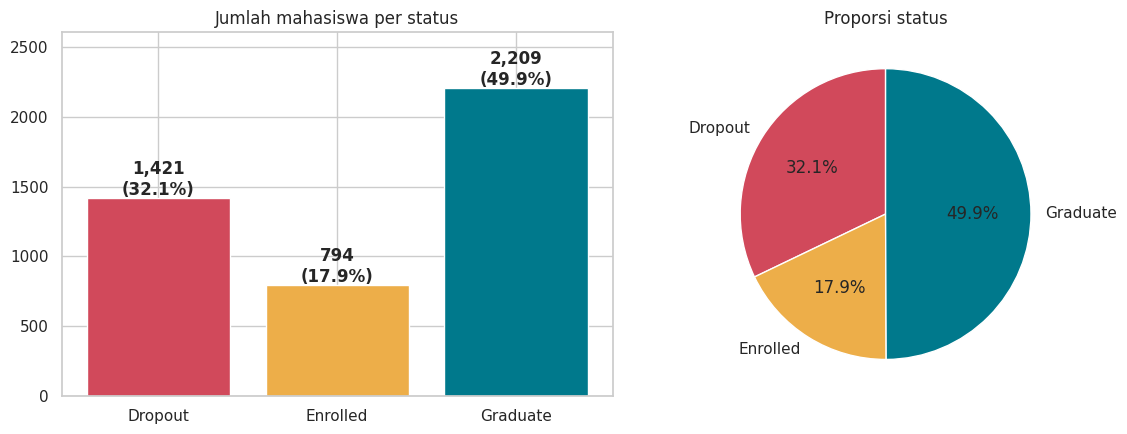

In [7]:
jumlah = df["Status"].value_counts().reindex(STATUS_ORDER)
persen = (jumlah / jumlah.sum() * 100).round(1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(jumlah.index, jumlah.values, color=[PALETTE[s] for s in jumlah.index])
for i, (n, p) in enumerate(zip(jumlah.values, persen.values)):
    ax[0].text(i, n + 20, f"{n:,}\n({p}%)", ha="center", fontweight="bold")
ax[0].set_ylim(0, jumlah.max() * 1.18)
ax[0].set_title("Jumlah mahasiswa per status")
ax[1].pie(jumlah.values, labels=jumlah.index, autopct="%1.1f%%", startangle=90,
          colors=[PALETTE[s] for s in jumlah.index], wedgeprops={"edgecolor": "white"})
ax[1].set_title("Proporsi status")
plt.tight_layout(); plt.show()

**Insight.** Sekitar 32% mahasiswa *dropout*. Hampir 1 dari 3 mahasiswa tidak menyelesaikan studi. Kelas `Enrolled` paling kecil (18%). Data cukup seimbang, tetapi kita tetap memakai pembobotan kelas saat modeling.

## 2.3 Distribusi fitur numerik

Kita melihat bentuk sebaran fitur kontinu. Warna menunjukkan status mahasiswa.

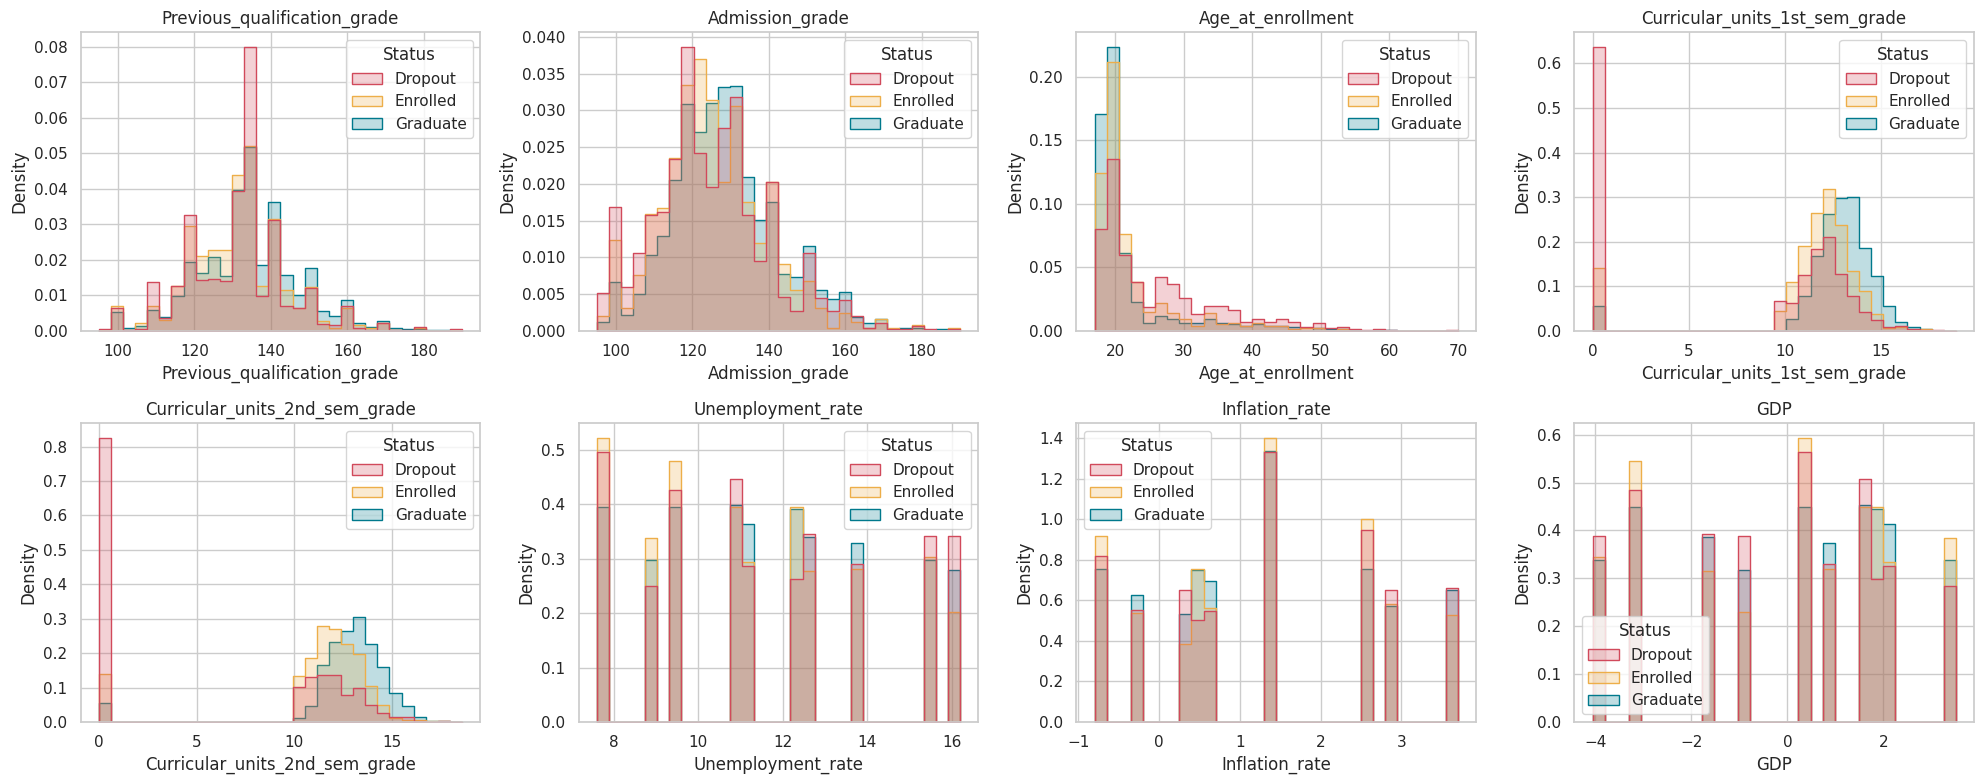

In [8]:
kontinu = ["Previous_qualification_grade", "Admission_grade", "Age_at_enrollment",
           "Curricular_units_1st_sem_grade", "Curricular_units_2nd_sem_grade",
           "Unemployment_rate", "Inflation_rate", "GDP"]

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), kontinu):
    sns.histplot(data=df, x=col, hue="Status", hue_order=STATUS_ORDER, palette=PALETTE,
                 bins=30, element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

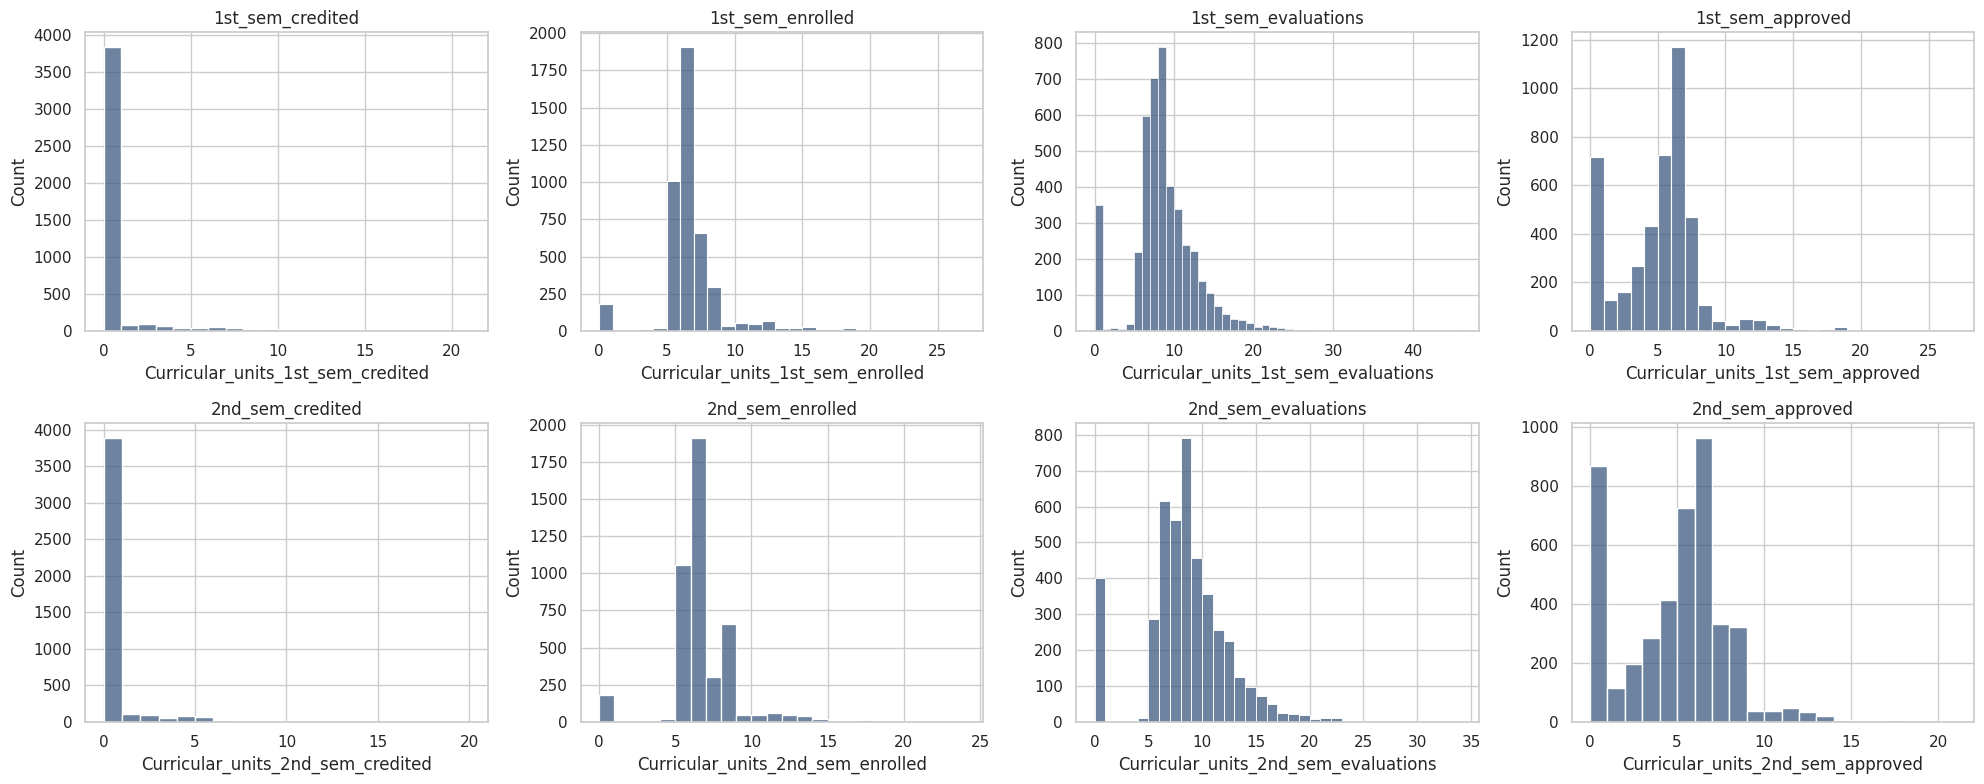

In [9]:
hitung = ["Curricular_units_1st_sem_credited", "Curricular_units_1st_sem_enrolled",
          "Curricular_units_1st_sem_evaluations", "Curricular_units_1st_sem_approved",
          "Curricular_units_2nd_sem_credited", "Curricular_units_2nd_sem_enrolled",
          "Curricular_units_2nd_sem_evaluations", "Curricular_units_2nd_sem_approved"]

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), hitung):
    sns.histplot(data=df, x=col, bins=range(0, int(df[col].max()) + 2), color="#3d5a80", ax=ax)
    ax.set_title(col.replace("Curricular_units_", ""))
plt.tight_layout(); plt.show()

**Insight.**
- Usia saat masuk condong ke kanan. Sebagian besar mahasiswa masuk di usia 18-20 tahun, tetapi ada kelompok dewasa hingga usia 70 tahun.
- Nilai semester 1 dan 2 punya lonjakan di angka 0. Mahasiswa dengan nilai 0 hampir tidak menyelesaikan mata kuliah apa pun.
- Indikator makroekonomi hanya punya beberapa nilai unik. Nilainya terikat pada periode pendaftaran, bukan pada individu.

## 2.4 Outlier (metode IQR)

In [10]:
kolom_outlier = [c for c in df.select_dtypes("number").columns
                 if c not in BINARY + NOMINAL and df[c].nunique() > 10]
baris = []
for c in kolom_outlier:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    baris.append({"fitur": c, "jumlah_outlier": n_out, "persen": n_out / len(df) * 100})
pd.DataFrame(baris).sort_values("jumlah_outlier", ascending=False).reset_index(drop=True)

,fitur,jumlah_outlier,persen
0,Curricular_units_2nd_sem_grade,877,19.824
1,Curricular_units_1st_sem_grade,726,16.410
2,Curricular_units_1st_sem_credited,577,13.042
3,Curricular_units_2nd_sem_credited,530,11.980
4,Age_at_enrollment,441,9.968
5,Curricular_units_1st_sem_enrolled,424,9.584
6,Curricular_units_2nd_sem_enrolled,369,8.341
7,Curricular_units_1st_sem_without_evaluations,294,6.646
8,Curricular_units_1st_sem_approved,180,4.069
9,Previous_qualification_grade,179,4.046


**Keputusan.** Outlier terbanyak muncul pada nilai semester 1 dan 2 (sekitar 16-20%). Penyebabnya angka 0 pada mahasiswa yang tidak mengikuti evaluasi. Outlier juga muncul pada mata kuliah yang dikreditkan dan pada usia (sekitar 10%). Nilai-nilai ini masuk akal secara bisnis (mahasiswa tanpa evaluasi, mahasiswa pindahan, mahasiswa dewasa). Kita **tidak menghapus** outlier. Model berbasis pohon tahan terhadap nilai ekstrem.

## 2.5 Faktor biner: siapa yang lebih sering dropout?

Grafik di bawah menampilkan komposisi status untuk tiap fitur biner. Angka `n` menunjukkan jumlah mahasiswa di tiap kelompok.

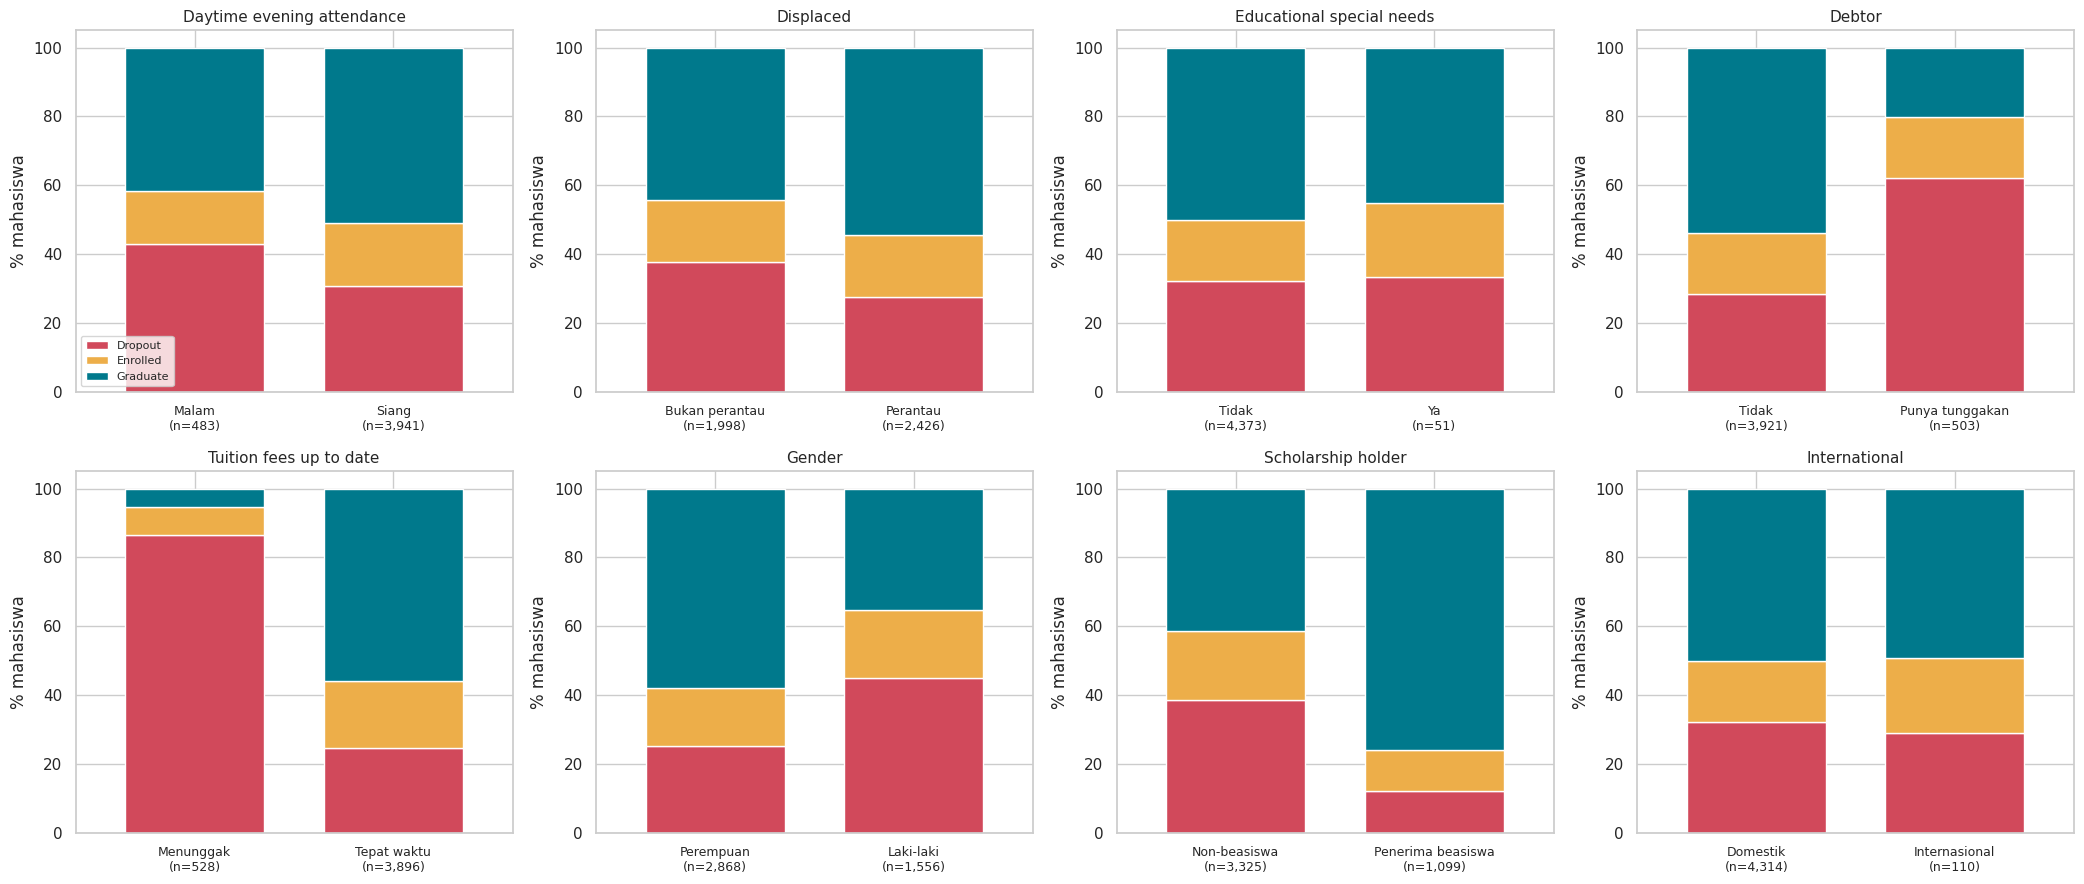

In [11]:
def tabel_rate(col, labels=None, data=None):
    data = df if data is None else data
    t = pd.crosstab(data[col], data["Status"]).reindex(columns=STATUS_ORDER, fill_value=0)
    out = pd.DataFrame({"n": t.sum(axis=1)})
    for s in STATUS_ORDER:
        out[f"{s}_%"] = t[s] / t.sum(axis=1) * 100
    if labels:
        out.index = out.index.map(lambda v: labels.get(v, v))
    return out

fig, axes = plt.subplots(2, 4, figsize=(21, 9))
for ax, col in zip(axes.ravel(), BINARY):
    t = tabel_rate(col, BIN_LABELS[col])
    plot = t[[f"{s}_%" for s in STATUS_ORDER]]
    plot.columns = STATUS_ORDER
    plot.plot(kind="bar", stacked=True, ax=ax, color=[PALETTE[s] for s in STATUS_ORDER], legend=False, width=0.7)
    ax.set_xticklabels([f"{i}\n(n={int(n):,})" for i, n in zip(t.index, t["n"])], rotation=0, fontsize=9)
    ax.set_title(col.replace("_", " "), fontsize=11)
    ax.set_xlabel(""); ax.set_ylabel("% mahasiswa")
axes[0, 0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

In [12]:
ringkas_biner = []
for col in BINARY:
    t = tabel_rate(col, BIN_LABELS[col])
    for idx, r in t.iterrows():
        ringkas_biner.append({"fitur": col, "kelompok": idx, "n": int(r["n"]),
                              "Dropout_%": r["Dropout_%"], "Graduate_%": r["Graduate_%"]})
pd.DataFrame(ringkas_biner)

,fitur,kelompok,n,Dropout_%,Graduate_%
0,Daytime_evening_attendance,Malam,483,42.857,41.615
1,Daytime_evening_attendance,Siang,3941,30.804,50.952
2,Displaced,Bukan perantau,1998,37.638,44.294
3,Displaced,Perantau,2426,27.576,54.575
4,Educational_special_needs,Tidak,4373,32.106,49.989
5,Educational_special_needs,Ya,51,33.333,45.098
6,Debtor,Tidak,3921,28.284,53.762
7,Debtor,Punya tunggakan,503,62.028,20.080
8,Tuition_fees_up_to_date,Menunggak,528,86.553,5.492
9,Tuition_fees_up_to_date,Tepat waktu,3896,24.743,55.955


**Insight.**
- **Pembayaran kuliah adalah sinyal terkuat.** Mahasiswa yang menunggak biaya kuliah punya tingkat dropout sekitar **87%**. Yang membayar tepat waktu hanya sekitar **25%**.
- **Debitur berisiko tinggi.** Tingkat dropout debitur mencapai sekitar **62%** (non-debitur 28%).
- **Beasiswa melindungi.** Penerima beasiswa dropout sekitar **12%**. Non-penerima sekitar **39%**.
- **Gender berpengaruh.** Mahasiswa laki-laki dropout sekitar **45%**. Mahasiswa perempuan sekitar **25%**.
- **Kelas malam lebih rentan.** Dropout kelas malam sekitar 43% dibanding 31% pada kelas siang.
- Status internasional dan kebutuhan khusus hampir tidak membedakan tingkat dropout. Kelompok ini juga sangat kecil (110 dan 51 mahasiswa).

## 2.6 Interaksi faktor keuangan

Kita menggabungkan pembayaran, beasiswa, dan status debitur. Heatmap menunjukkan persentase dropout di tiap kombinasi.

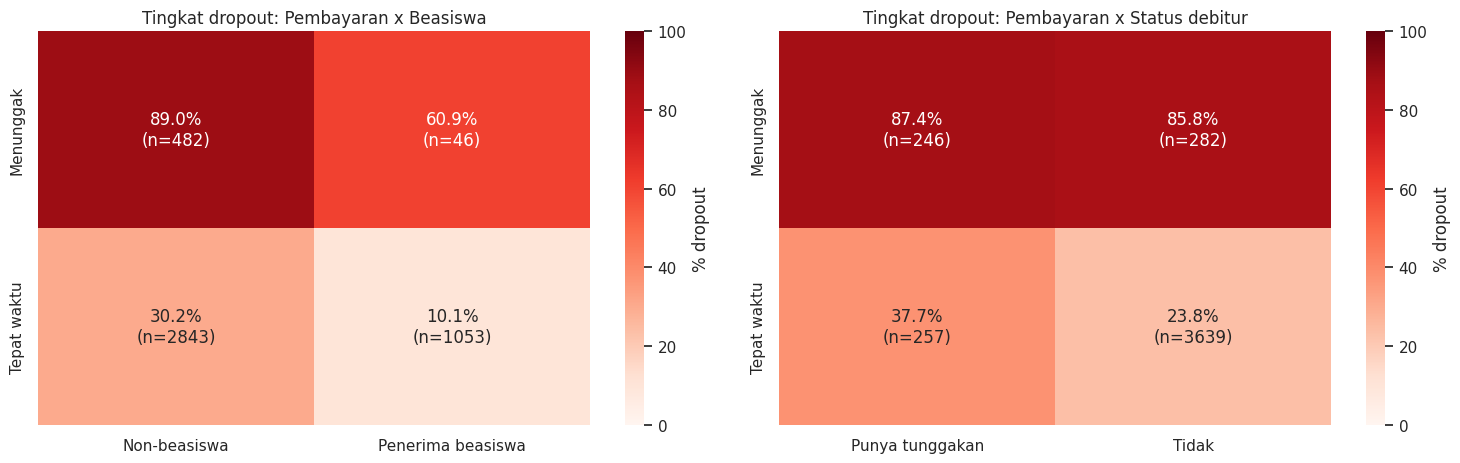

In [14]:
tmp = df.copy()
tmp["is_dropout"] = (tmp["Status"] == "Dropout").astype(int)
tmp["Pembayaran"] = tmp["Tuition_fees_up_to_date"].map(BIN_LABELS["Tuition_fees_up_to_date"])
tmp["Beasiswa"] = tmp["Scholarship_holder"].map(BIN_LABELS["Scholarship_holder"])
tmp["Debitur"] = tmp["Debtor"].map(BIN_LABELS["Debtor"])

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for a, (idx, colm, ttl) in zip(ax, [("Pembayaran", "Beasiswa", "Pembayaran x Beasiswa"),
                                    ("Pembayaran", "Debitur", "Pembayaran x Status debitur")]):
    rate = tmp.pivot_table(index=idx, columns=colm, values="is_dropout", aggfunc="mean") * 100
    cnt = tmp.pivot_table(index=idx, columns=colm, values="is_dropout", aggfunc="size")
    anot = rate.round(1).astype(str) + "%\n(n=" + cnt.astype(str) + ")"
    sns.heatmap(rate, annot=anot, fmt="", cmap="Reds", vmin=0, vmax=100, cbar_kws={"label": "% dropout"}, ax=a)
    a.set_title(f"Tingkat dropout: {ttl}"); a.set_xlabel(""); a.set_ylabel("")
plt.tight_layout(); plt.show()

**Insight.** Beasiswa menurunkan risiko di kedua kelompok pembayaran. Namun mahasiswa penunggak tetap berisiko sangat tinggi, bahkan dengan beasiswa. Masalah keuangan perlu ditangani langsung, tidak cukup dengan beasiswa saja.

## 2.7 Program studi dan jalur pendaftaran

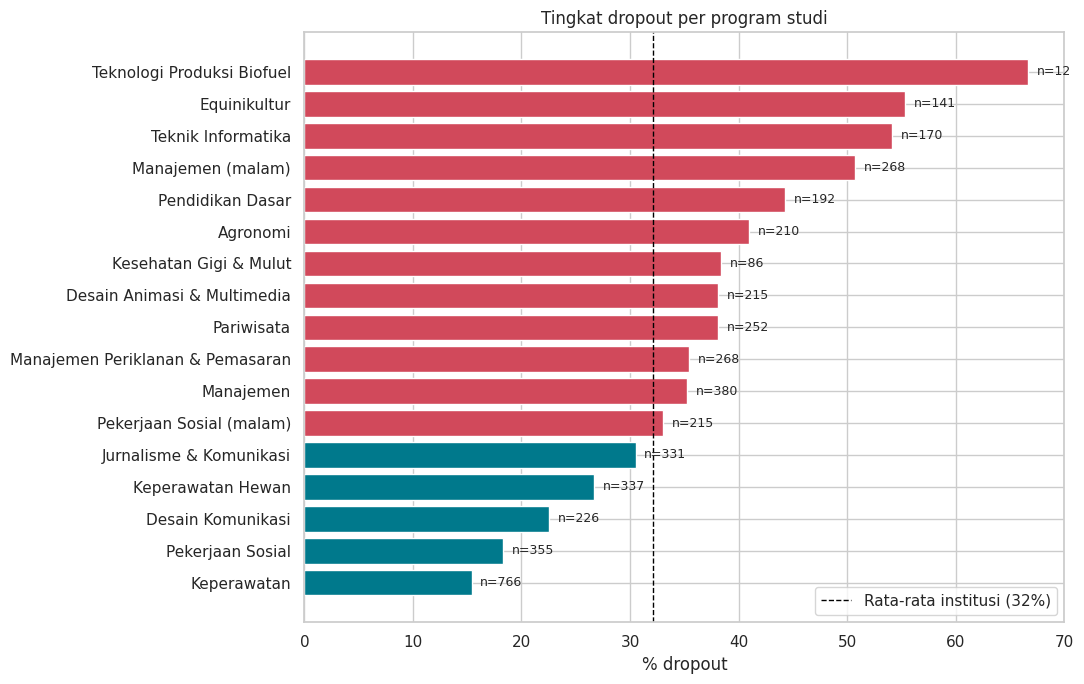

In [15]:
tc = tabel_rate("Course", COURSE).sort_values("Dropout_%")
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(tc.index, tc["Dropout_%"], color=np.where(tc["Dropout_%"] > 32.1, "#d1495b", "#00798c"))
for b, n in zip(bars, tc["n"]):
    ax.text(b.get_width() + 0.8, b.get_y() + b.get_height() / 2, f"n={int(n)}", va="center", fontsize=9)
ax.axvline(df["Status"].eq("Dropout").mean() * 100, color="black", ls="--", lw=1, label="Rata-rata institusi (32%)")
ax.set_xlabel("% dropout"); ax.set_title("Tingkat dropout per program studi")
ax.legend(); plt.tight_layout(); plt.show()

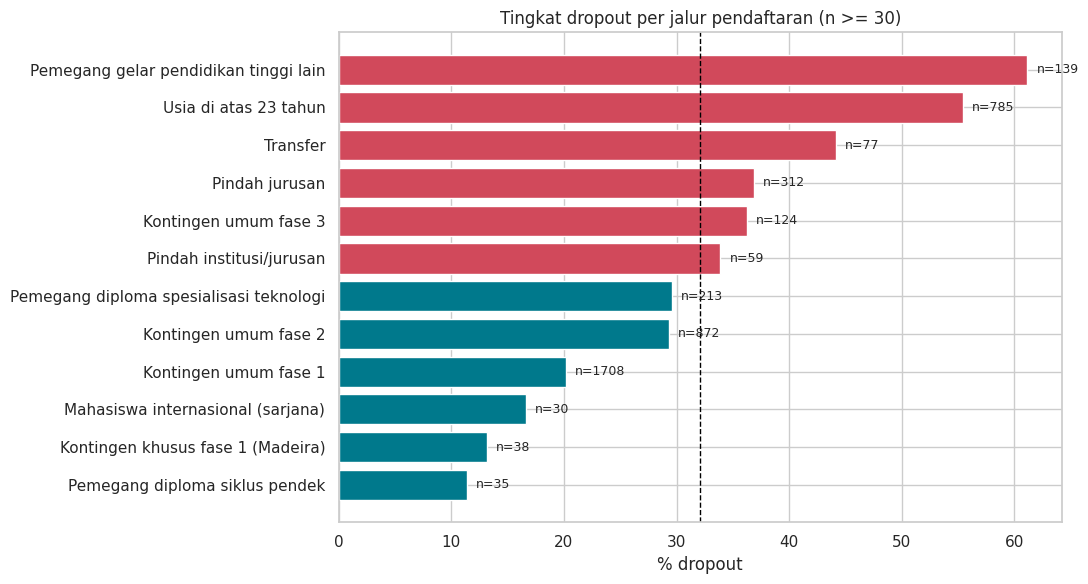

In [16]:
tm = tabel_rate("Application_mode", APP_MODE)
tm = tm[tm["n"] >= 30].sort_values("Dropout_%")
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(tm.index, tm["Dropout_%"], color=np.where(tm["Dropout_%"] > 32.1, "#d1495b", "#00798c"))
for b, n in zip(bars, tm["n"]):
    ax.text(b.get_width() + 0.8, b.get_y() + b.get_height() / 2, f"n={int(n)}", va="center", fontsize=9)
ax.axvline(32.1, color="black", ls="--", lw=1)
ax.set_xlabel("% dropout"); ax.set_title("Tingkat dropout per jalur pendaftaran (n >= 30)")
plt.tight_layout(); plt.show()

**Insight.**
- Tingkat dropout sangat bervariasi antar program. **Keperawatan (9500)** hanya sekitar 15%. **Teknik Informatika (9119)**, **Equinikultur (9130)**, dan **Manajemen kelas malam (9991)** berada di atas 50%.
- Jalur pendaftaran **usia di atas 23 tahun** (sekitar 55%) dan **pemegang gelar lain** (sekitar 61%) paling berisiko. Jalur **kontingen umum fase 1** hanya sekitar 20%.
- Program dengan dropout tinggi perlu intervensi khusus pada program tersebut.

## 2.8 Usia dan latar belakang pendidikan

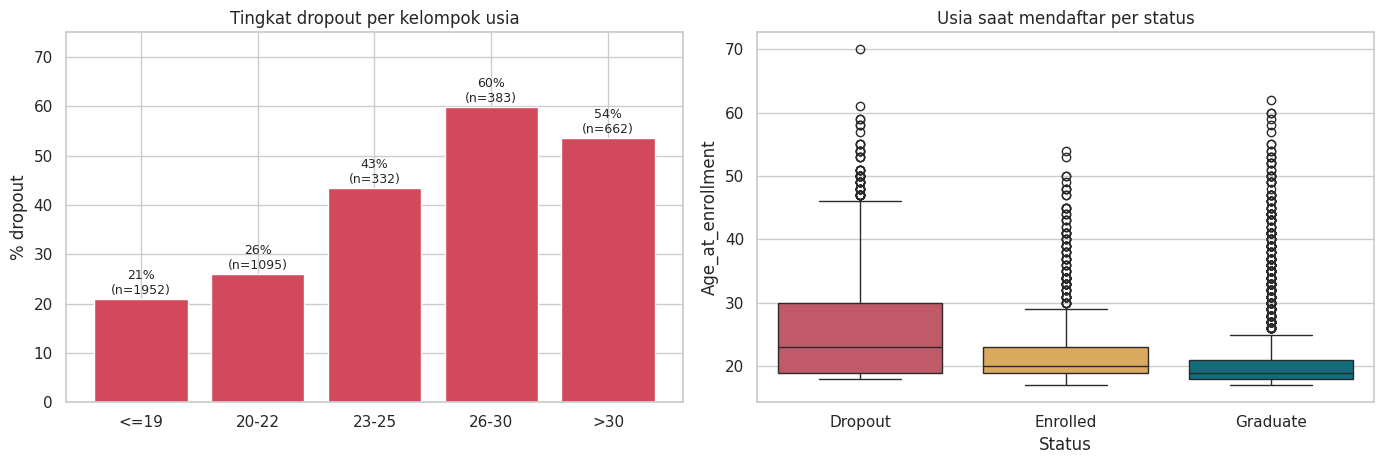

In [17]:
tmp["Kelompok_usia"] = pd.cut(tmp["Age_at_enrollment"], [0, 19, 22, 25, 30, 100],
                              labels=["<=19", "20-22", "23-25", "26-30", ">30"])
ta = tmp.groupby("Kelompok_usia", observed=True)["is_dropout"].agg(["mean", "size"])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].bar(ta.index.astype(str), ta["mean"] * 100, color="#d1495b")
for i, (m, n) in enumerate(zip(ta["mean"], ta["size"])):
    ax[0].text(i, m * 100 + 1, f"{m*100:.0f}%\n(n={n})", ha="center", fontsize=9)
ax[0].set_ylim(0, 75); ax[0].set_title("Tingkat dropout per kelompok usia"); ax[0].set_ylabel("% dropout")

sns.boxplot(data=df, x="Status", y="Age_at_enrollment", order=STATUS_ORDER, palette=PALETTE, ax=ax[1])
ax[1].set_title("Usia saat mendaftar per status")
plt.tight_layout(); plt.show()

In [18]:
mq = df["Mothers_qualification"].value_counts().head(8).index
tq = tabel_rate("Mothers_qualification", data=df[df["Mothers_qualification"].isin(mq)])
tq.index.name = "Kode pendidikan ibu"
tq.sort_values("Dropout_%")

,n,Dropout_%,Enrolled_%,Graduate_%
Kode pendidikan ibu,,,,
4,49,16.327,30.612,53.061
2,83,24.096,27.711,48.193
38,562,24.911,16.192,58.897
1,1069,28.064,19.083,52.853
19,953,28.437,18.468,53.095
3,438,31.735,23.059,45.205
37,1009,37.958,16.749,45.292
34,130,73.846,2.308,23.846


**Insight.** Risiko naik tajam setelah usia 22 tahun. Dropout melewati 43% pada usia 23-25 tahun dan mendekati 60% pada usia 26-30 tahun. Mahasiswa dewasa umumnya bekerja atau punya tanggungan. Pendidikan orang tua menunjukkan pola yang lemah. Tingkat dropout hampir semua kelompok pendidikan ibu berkisar 16-38%. Satu kelompok kecil (kode 34, n=130) mencapai sekitar 74%. Tim data perlu memeriksa apakah kode ini berarti data tidak diketahui.

## 2.9 Kinerja akademik

Kinerja semester 1 dan 2 adalah kelompok fitur yang paling informatif.

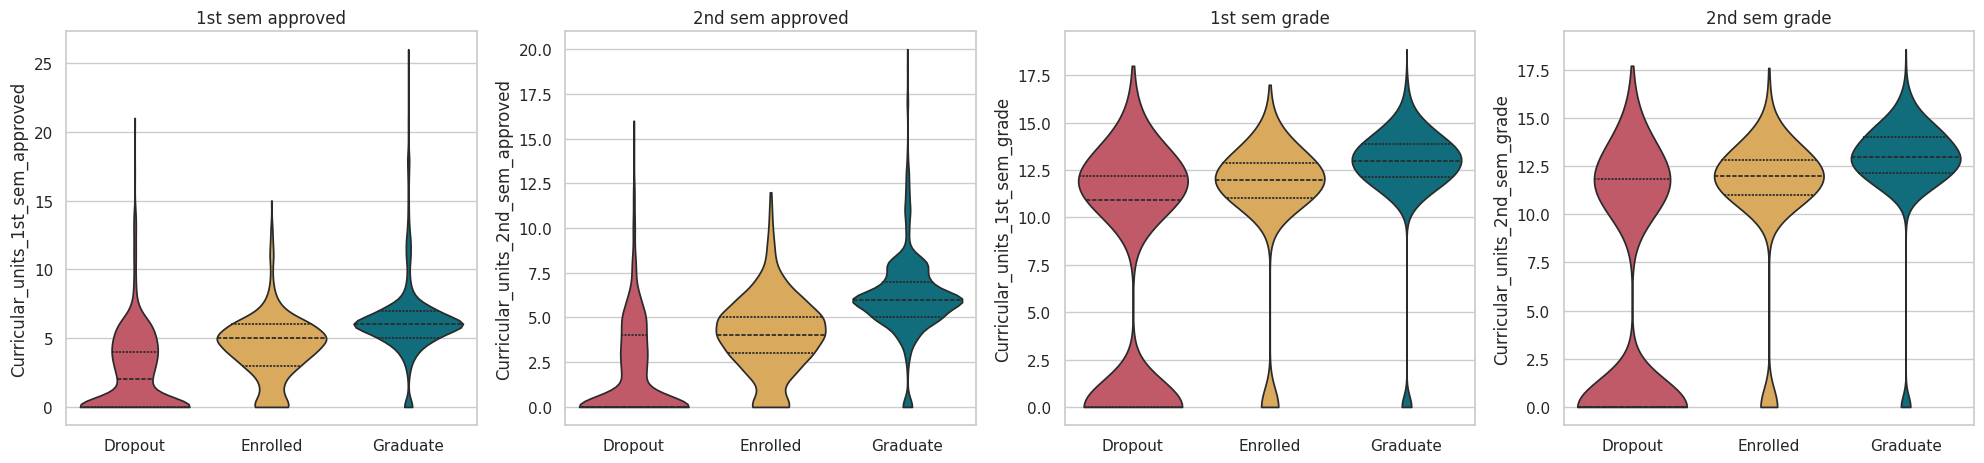

,Curricular_units_1st_sem_approved,Curricular_units_2nd_sem_approved,Curricular_units_1st_sem_grade,Curricular_units_2nd_sem_grade
Status,,,,
Dropout,2.550,1.940,7.260,5.900
Enrolled,4.320,4.060,11.130,11.120
Graduate,6.230,6.180,12.640,12.700


In [20]:
akad = ["Curricular_units_1st_sem_approved", "Curricular_units_2nd_sem_approved",
        "Curricular_units_1st_sem_grade", "Curricular_units_2nd_sem_grade"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
for ax, col in zip(axes, akad):
    sns.violinplot(data=df, x="Status", y=col, order=STATUS_ORDER, palette=PALETTE, inner="quartile", cut=0, ax=ax)
    ax.set_title(col.replace("Curricular_units_", "").replace("_", " "))
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

df.groupby("Status")[akad].mean().reindex(STATUS_ORDER).round(2)

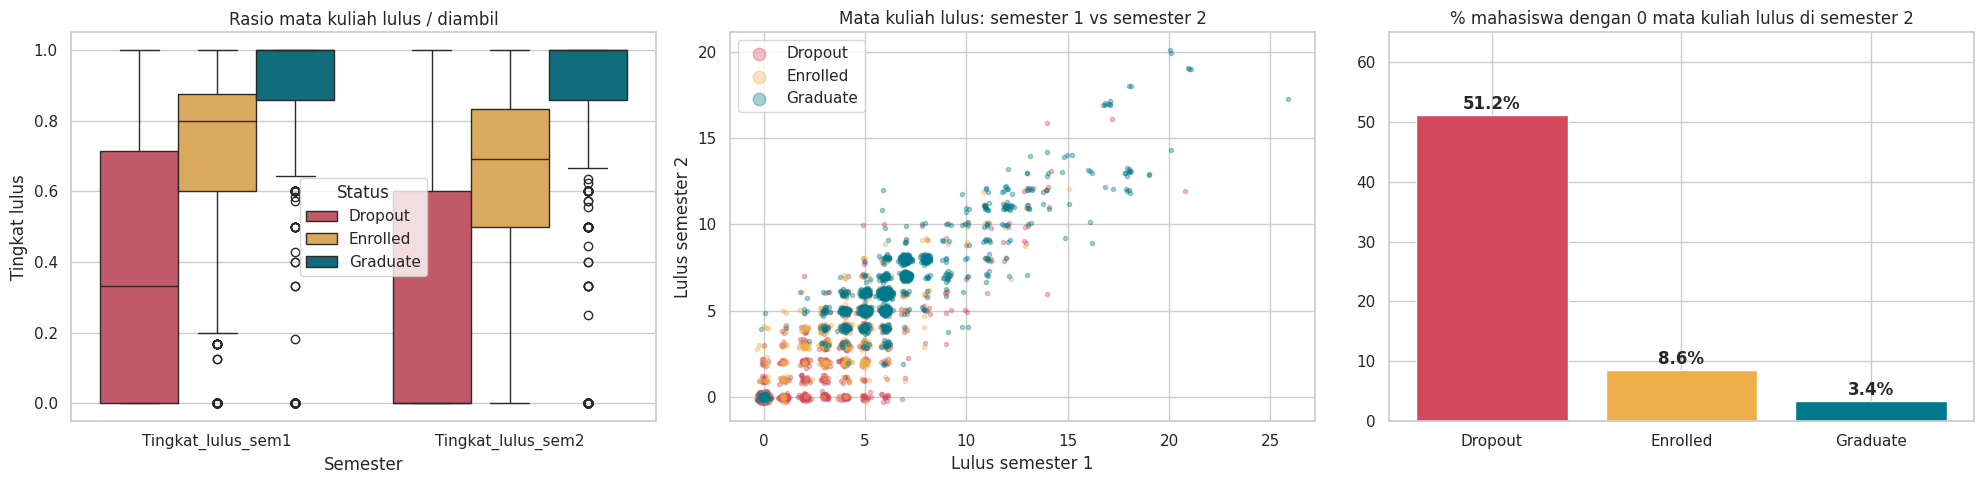

In [21]:
d = df.copy()
d["Tingkat_lulus_sem1"] = np.where(d["Curricular_units_1st_sem_enrolled"] > 0,
                                   d["Curricular_units_1st_sem_approved"] / d["Curricular_units_1st_sem_enrolled"], 0)
d["Tingkat_lulus_sem2"] = np.where(d["Curricular_units_2nd_sem_enrolled"] > 0,
                                   d["Curricular_units_2nd_sem_approved"] / d["Curricular_units_2nd_sem_enrolled"], 0)

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
sns.boxplot(data=d.melt(id_vars="Status", value_vars=["Tingkat_lulus_sem1", "Tingkat_lulus_sem2"], var_name="Semester", value_name="Tingkat lulus"),
            x="Semester", y="Tingkat lulus", hue="Status", hue_order=STATUS_ORDER, palette=PALETTE, ax=ax[0])
ax[0].set_title("Rasio mata kuliah lulus / diambil")

rng = np.random.default_rng(RANDOM_STATE)
for s in STATUS_ORDER:
    sub = d[d["Status"] == s]
    ax[1].scatter(sub["Curricular_units_1st_sem_approved"] + rng.normal(0, .12, len(sub)),
                  sub["Curricular_units_2nd_sem_approved"] + rng.normal(0, .12, len(sub)),
                  s=9, alpha=.35, color=PALETTE[s], label=s)
ax[1].set_xlabel("Lulus semester 1"); ax[1].set_ylabel("Lulus semester 2")
ax[1].set_title("Mata kuliah lulus: semester 1 vs semester 2"); ax[1].legend(markerscale=3)

nol = (d["Curricular_units_2nd_sem_approved"] == 0).groupby(d["Status"]).mean().reindex(STATUS_ORDER) * 100
ax[2].bar(nol.index, nol.values, color=[PALETTE[s] for s in nol.index])
for i, v in enumerate(nol.values):
    ax[2].text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")
ax[2].set_title("% mahasiswa dengan 0 mata kuliah lulus di semester 2"); ax[2].set_ylim(0, 65)
plt.tight_layout(); plt.show()

**Insight.**
- Rata-rata mata kuliah lulus semester 1: **Dropout 2,6**, **Enrolled 4,3**, **Graduate 6,2**. Pola yang sama muncul di semester 2.
- Rata-rata nilai semester 2: **Dropout 5,9** dibanding **12,7** untuk Graduate. Nilai dropout tertarik turun oleh banyak angka 0.
- Sekitar **51% mahasiswa dropout tidak lulus satu pun mata kuliah di semester 2**. Pada Graduate angkanya hanya 3%.
- Mahasiswa `Enrolled` berada di tengah. Mereka lebih mirip Graduate dalam nilai, tetapi lulus lebih sedikit mata kuliah. Karena itu kelas ini paling sulit diprediksi.
- Penurunan dari semester 1 ke semester 2 menjadi tanda peringatan. Kita menambahkan fitur tren pada tahap Data Preparation.

## 2.10 Prestasi sebelum kuliah dan nilai masuk

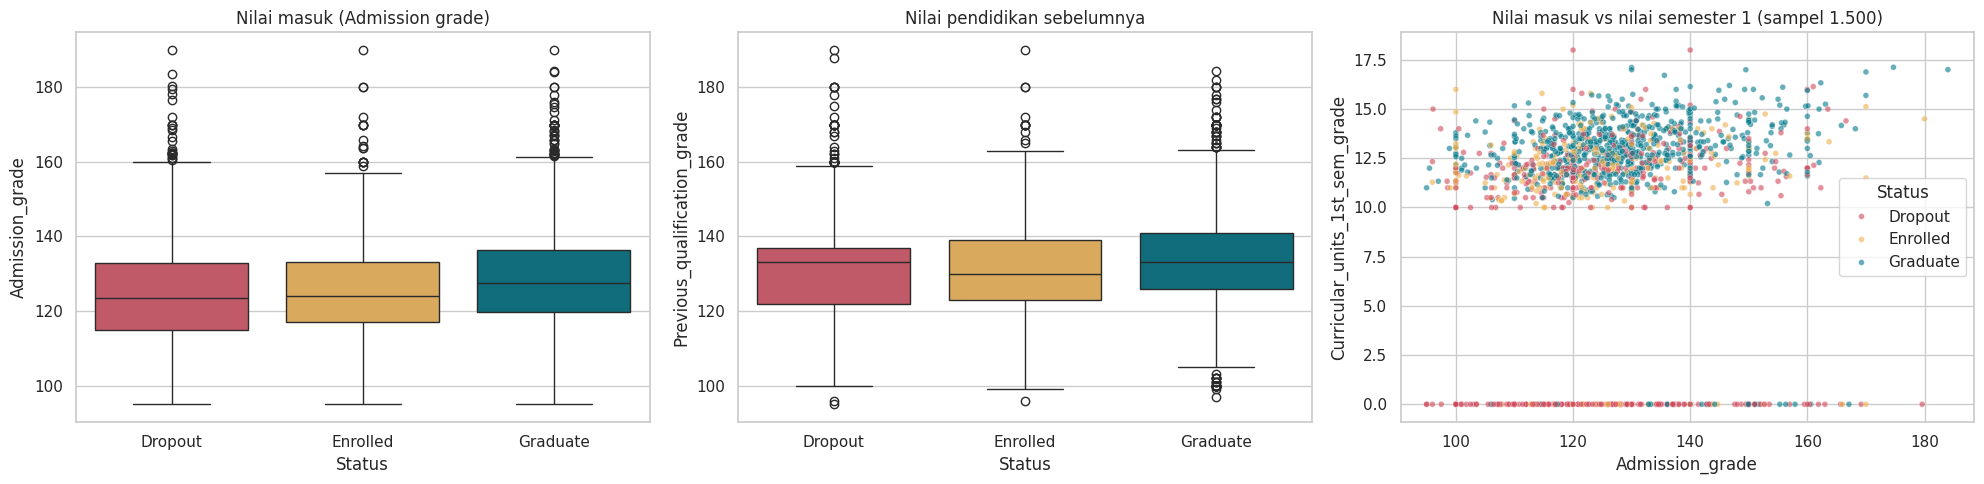

Korelasi Admission_grade vs nilai semester 1: 0.074


In [22]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
sns.boxplot(data=df, x="Status", y="Admission_grade", order=STATUS_ORDER, palette=PALETTE, ax=ax[0])
ax[0].set_title("Nilai masuk (Admission grade)")
sns.boxplot(data=df, x="Status", y="Previous_qualification_grade", order=STATUS_ORDER, palette=PALETTE, ax=ax[1])
ax[1].set_title("Nilai pendidikan sebelumnya")
sns.scatterplot(data=df.sample(1500, random_state=RANDOM_STATE), x="Admission_grade",
                y="Curricular_units_1st_sem_grade", hue="Status", hue_order=STATUS_ORDER,
                palette=PALETTE, alpha=.6, s=18, ax=ax[2])
ax[2].set_title("Nilai masuk vs nilai semester 1 (sampel 1.500)")
plt.tight_layout(); plt.show()

print("Korelasi Admission_grade vs nilai semester 1:",
      round(df["Admission_grade"].corr(df["Curricular_units_1st_sem_grade"]), 3))

**Insight.** Nilai masuk dan nilai pendidikan sebelumnya hanya berbeda tipis antar status. Prestasi sebelum kuliah **tidak banyak menjelaskan** dropout. Kinerja di kampus lebih menentukan.

## 2.11 Indikator makroekonomi

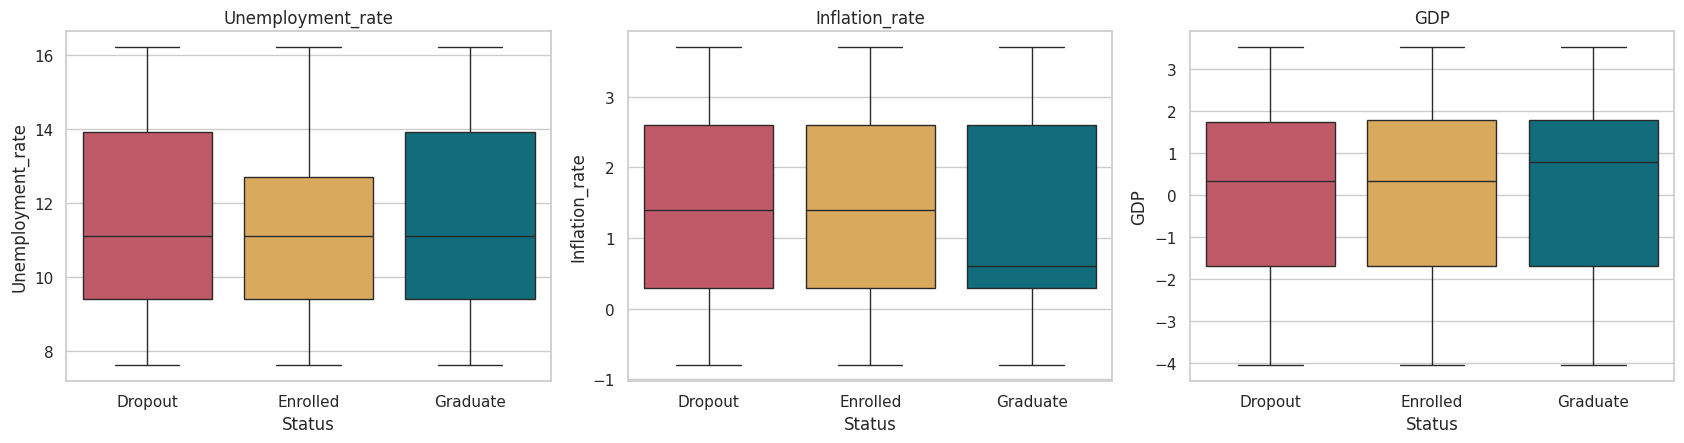

Nilai unik per indikator: {'Unemployment_rate': 10, 'Inflation_rate': 9, 'GDP': 10}


,Unemployment_rate,Inflation_rate,GDP
Status,,,
Dropout,11.620,1.280,-0.150
Enrolled,11.270,1.210,0.050
Graduate,11.640,1.200,0.080


In [23]:
macro = ["Unemployment_rate", "Inflation_rate", "GDP"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, col in zip(axes, macro):
    sns.boxplot(data=df, x="Status", y=col, order=STATUS_ORDER, palette=PALETTE, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

print("Nilai unik per indikator:", {c: df[c].nunique() for c in macro})
df.groupby("Status")[macro].mean().reindex(STATUS_ORDER).round(2)

**Insight.** Perbedaan antar status kecil. Indikator makro hanya punya sedikit nilai unik, sehingga bertindak sebagai penanda periode pendaftaran. Kita menyimpannya sebagai fitur, tetapi tidak berharap kontribusi besar.

## 2.12 Korelasi antar fitur

Kita menghitung korelasi Pearson untuk fitur numerik dan biner. Kolom nominal (misalnya `Course`) dikecualikan karena urutan kodenya tidak bermakna.

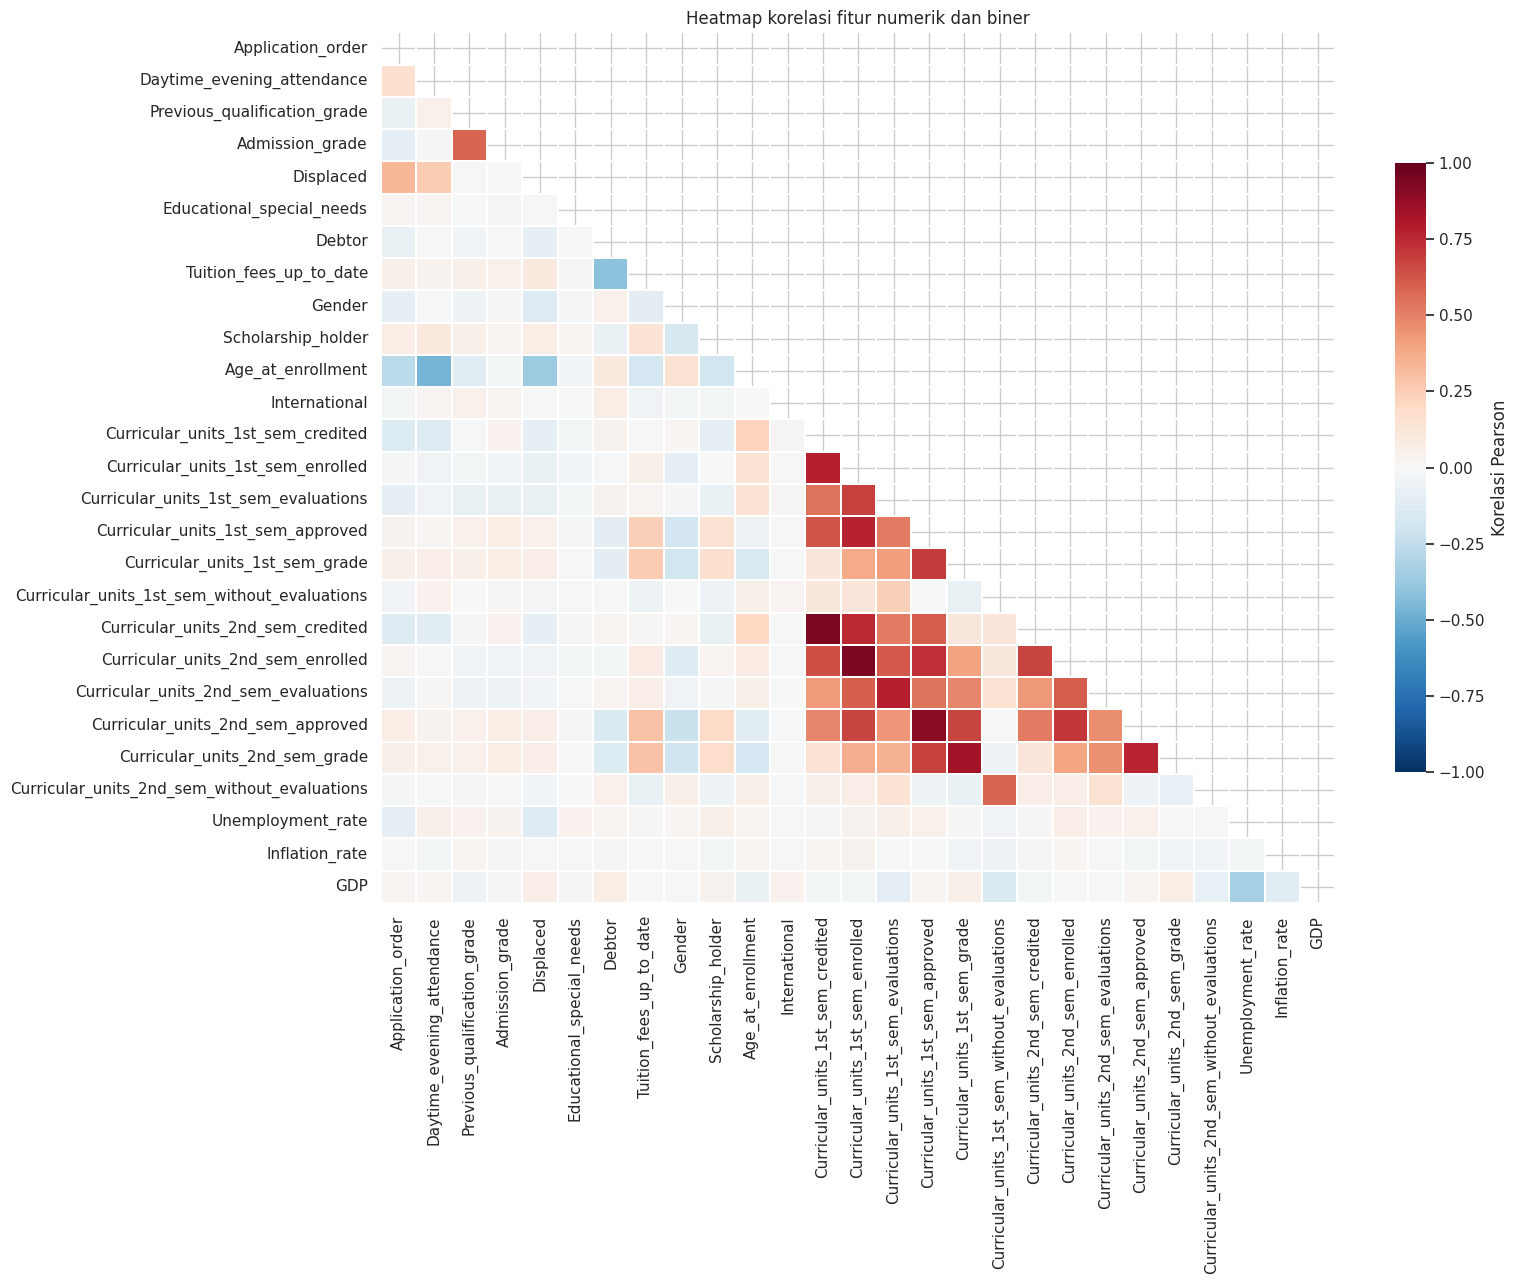

In [24]:
fitur_korelasi = [c for c in df.select_dtypes("number").columns if c not in NOMINAL]
corr = df[fitur_korelasi].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=.3,
            cbar_kws={"shrink": .7, "label": "Korelasi Pearson"}, ax=ax)
ax.set_title("Heatmap korelasi fitur numerik dan biner")
plt.tight_layout(); plt.show()

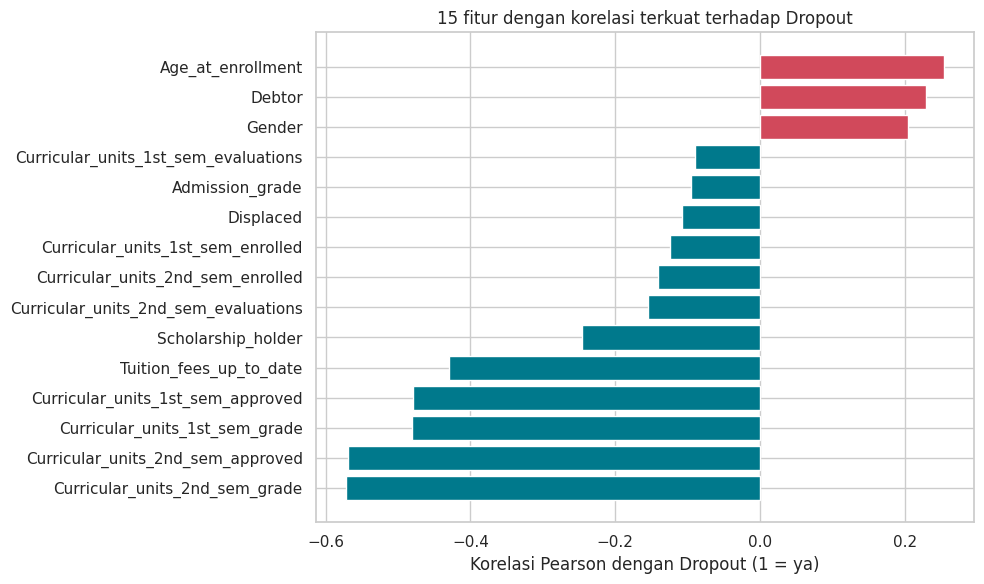

,corr_Dropout,corr_Enrolled,corr_Graduate
Curricular_units_2nd_sem_grade,-0.572,0.080,0.473
Curricular_units_2nd_sem_approved,-0.570,-0.059,0.577
Curricular_units_1st_sem_grade,-0.481,0.047,0.413
Curricular_units_1st_sem_approved,-0.479,-0.059,0.492
Tuition_fees_up_to_date,-0.429,0.096,0.327
Age_at_enrollment,0.254,-0.055,-0.195
Scholarship_holder,-0.245,-0.092,0.299
Debtor,0.229,-0.001,-0.214
Gender,0.204,0.034,-0.217
Curricular_units_2nd_sem_evaluations,-0.155,0.163,0.020


In [25]:
y_flags = pd.get_dummies(df["Status"]).astype(int)
corr_target = pd.DataFrame({
    f"corr_{s}": df[fitur_korelasi].corrwith(y_flags[s]) for s in STATUS_ORDER
})

top = corr_target["corr_Dropout"].abs().sort_values(ascending=False).head(15).index
plot = corr_target.loc[top, "corr_Dropout"].sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot.index, plot.values, color=np.where(plot.values > 0, "#d1495b", "#00798c"))
ax.set_title("15 fitur dengan korelasi terkuat terhadap Dropout")
ax.set_xlabel("Korelasi Pearson dengan Dropout (1 = ya)")
plt.tight_layout(); plt.show()

corr_target.loc[top].round(3)

In [26]:
pasangan = (corr.where(~mask).stack().rename("korelasi").reset_index()
            .rename(columns={"level_0": "fitur_1", "level_1": "fitur_2"}))
pasangan["abs"] = pasangan["korelasi"].abs()
pasangan[pasangan["abs"] > 0.8].sort_values("abs", ascending=False).drop(columns="abs").reset_index(drop=True)

,fitur_1,fitur_2,korelasi
0,Curricular_units_2nd_sem_credited,Curricular_units_1st_sem_credited,0.945
1,Curricular_units_2nd_sem_enrolled,Curricular_units_1st_sem_enrolled,0.943
2,Curricular_units_2nd_sem_approved,Curricular_units_1st_sem_approved,0.904
3,Curricular_units_2nd_sem_grade,Curricular_units_1st_sem_grade,0.837


**Insight.**
- Fitur dengan korelasi negatif terkuat terhadap dropout: **mata kuliah lulus semester 2 (-0,57)**, **nilai semester 2 (-0,57)**, **mata kuliah lulus semester 1 (-0,48)**, **nilai semester 1 (-0,48)**, dan **pembayaran tepat waktu (-0,43)**.
- Fitur dengan korelasi positif: **usia saat mendaftar (+0,25)**, **status debitur (+0,23)**, dan **gender laki-laki (+0,20)**.
- Pasangan fitur semester 1 dan semester 2 berkorelasi tinggi (di atas 0,8). Multikolinearitas ini tidak mengganggu model pohon. Untuk Logistic Regression, kita memakai regularisasi bawaan.

## 2.13 Uji statistik hubungan fitur dengan Status

Korelasi hanya menangkap hubungan linear. Kita menambah dua uji:
- **Chi-square + Cramér's V** untuk fitur kategorikal dan biner.
- **Kruskal-Wallis + epsilon-squared** untuk fitur numerik.

Semakin besar efek, semakin kuat hubungan fitur dengan status.

In [27]:
hasil = []
n = len(df)
for c in BINARY + NOMINAL:
    tab = pd.crosstab(df[c], df["Status"])
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    v = np.sqrt(chi2 / (n * (min(tab.shape) - 1)))
    hasil.append({"fitur": c, "uji": "Chi-square", "p_value": p, "ukuran_efek": v})

num_cols = [c for c in df.columns if c not in BINARY + NOMINAL + ["Status"]]
for c in num_cols:
    grup = [g[c].values for _, g in df.groupby("Status")]
    h, p = stats.kruskal(*grup)
    eps = (h - len(grup) + 1) / (n - len(grup))
    hasil.append({"fitur": c, "uji": "Kruskal-Wallis", "p_value": p, "ukuran_efek": eps})

uji = pd.DataFrame(hasil).sort_values("ukuran_efek", ascending=False).reset_index(drop=True)
uji["signifikan (p<0.05)"] = np.where(uji["p_value"] < 0.05, "Ya", "Tidak")
uji.head(20)

,fitur,uji,p_value,ukuran_efek,signifikan (p<0.05)
0,Tuition_fees_up_to_date,Chi-square,0.000,0.431,Ya
1,Curricular_units_2nd_sem_approved,Kruskal-Wallis,0.000,0.428,Ya
2,Curricular_units_1st_sem_approved,Kruskal-Wallis,0.000,0.353,Ya
3,Curricular_units_2nd_sem_grade,Kruskal-Wallis,0.000,0.314,Ya
4,Scholarship_holder,Chi-square,0.000,0.304,Ya
5,Course,Chi-square,0.000,0.251,Ya
6,Curricular_units_1st_sem_grade,Kruskal-Wallis,0.000,0.247,Ya
7,Debtor,Chi-square,0.000,0.242,Ya
8,Gender,Chi-square,0.000,0.230,Ya
9,Application_mode,Chi-square,0.000,0.230,Ya


In [28]:
uji[uji["signifikan (p<0.05)"] == "Tidak"][["fitur", "uji", "p_value", "ukuran_efek"]]

,fitur,uji,p_value,ukuran_efek
19,Nacionality,Chi-square,0.242,0.072
24,International,Chi-square,0.527,0.017
27,Educational_special_needs,Chi-square,0.725,0.012
34,Inflation_rate,Kruskal-Wallis,0.296,0.000
35,Curricular_units_1st_sem_credited,Kruskal-Wallis,0.300,0.000


**Insight.** Fitur akademik semester 2 dan semester 1, status pembayaran, program studi, jalur pendaftaran, dan beasiswa memiliki ukuran efek terbesar. Lima fitur tidak signifikan pada taraf 5%: `Nacionality`, `International`, `Educational_special_needs`, `Inflation_rate`, dan `Curricular_units_1st_sem_credited`. Kontribusinya kecil. Kita tetap menyertakannya dan membiarkan model memutuskan.

## 2.14 Ringkasan insight EDA

| # | Temuan | Dampak bisnis |
|---|--------|---------------|
| 1 | Sekitar 32% mahasiswa dropout. | Masalah besar dan layak ditangani. |
| 2 | Menunggak uang kuliah berarti sekitar 87% dropout. | Sinyal paling jelas untuk intervensi finansial. |
| 3 | Beasiswa menurunkan dropout dari 39% ke 12%. | Perluasan beasiswa tepat sasaran efektif. |
| 4 | Sekitar 51% dropout tidak lulus satu pun mata kuliah di semester 2. | Pantau kelulusan mata kuliah sejak semester 1. |
| 5 | Risiko naik tajam setelah usia 22 tahun. | Mahasiswa dewasa butuh layanan khusus. |
| 6 | Program tertentu punya dropout di atas 50%. | Evaluasi kurikulum dan dukungan per program. |
| 7 | Nilai masuk dan indikator makro lemah pengaruhnya. | Fokus pada perilaku di kampus, bukan latar belakang akademik awal. |

# 3. Data Preparation

Tahap ini menyiapkan data untuk model. Kita melakukan empat hal:
1. Membuat fitur turunan dari kinerja akademik.
2. Meng-encode target.
3. Memisahkan fitur numerik, biner, dan nominal.
4. Membagi data latih dan data uji.

## 3.1 Feature engineering

Fitur turunan menangkap efisiensi belajar dan tren antar semester. Fungsi ini juga dipakai di `app.py`, sehingga perhitungan di aplikasi sama dengan saat pelatihan.

In [29]:
def tambah_fitur(data: pd.DataFrame) -> pd.DataFrame:
    """Menambah fitur turunan dari kinerja akademik semester 1 dan 2."""
    out = data.copy()
    for s, nama in [("1st", "sem1"), ("2nd", "sem2")]:
        enrolled = out[f"Curricular_units_{s}_sem_enrolled"]
        approved = out[f"Curricular_units_{s}_sem_approved"]
        out[f"approval_rate_{nama}"] = np.where(enrolled > 0, approved / enrolled.where(enrolled > 0, 1), 0.0)
    out["total_approved"] = (out["Curricular_units_1st_sem_approved"]
                             + out["Curricular_units_2nd_sem_approved"])
    out["total_enrolled"] = (out["Curricular_units_1st_sem_enrolled"]
                             + out["Curricular_units_2nd_sem_enrolled"])
    out["grade_trend"] = (out["Curricular_units_2nd_sem_grade"]
                          - out["Curricular_units_1st_sem_grade"])
    out["approved_trend"] = (out["Curricular_units_2nd_sem_approved"]
                             - out["Curricular_units_1st_sem_approved"])
    return out


FITUR_TURUNAN = ["approval_rate_sem1", "approval_rate_sem2", "total_approved",
                 "total_enrolled", "grade_trend", "approved_trend"]

df_fe = tambah_fitur(df)
df_fe[FITUR_TURUNAN].describe().T

,count,mean,std,min,25%,50%,75%,max
approval_rate_sem1,"4,424.000",0.698,0.365,0.000,0.500,0.833,1.000,1.000
approval_rate_sem2,"4,424.000",0.660,0.383,0.000,0.400,0.833,1.000,1.000
total_approved,"4,424.000",9.142,5.961,0.000,5.000,10.000,12.000,43.000
total_enrolled,"4,424.000",12.503,4.609,0.000,10.000,12.000,14.000,46.000
grade_trend,"4,424.000",-0.411,2.890,-16.143,-0.600,0.000,0.452,16.000
approved_trend,"4,424.000",-0.271,1.341,-9.000,-1.000,0.000,0.000,6.000


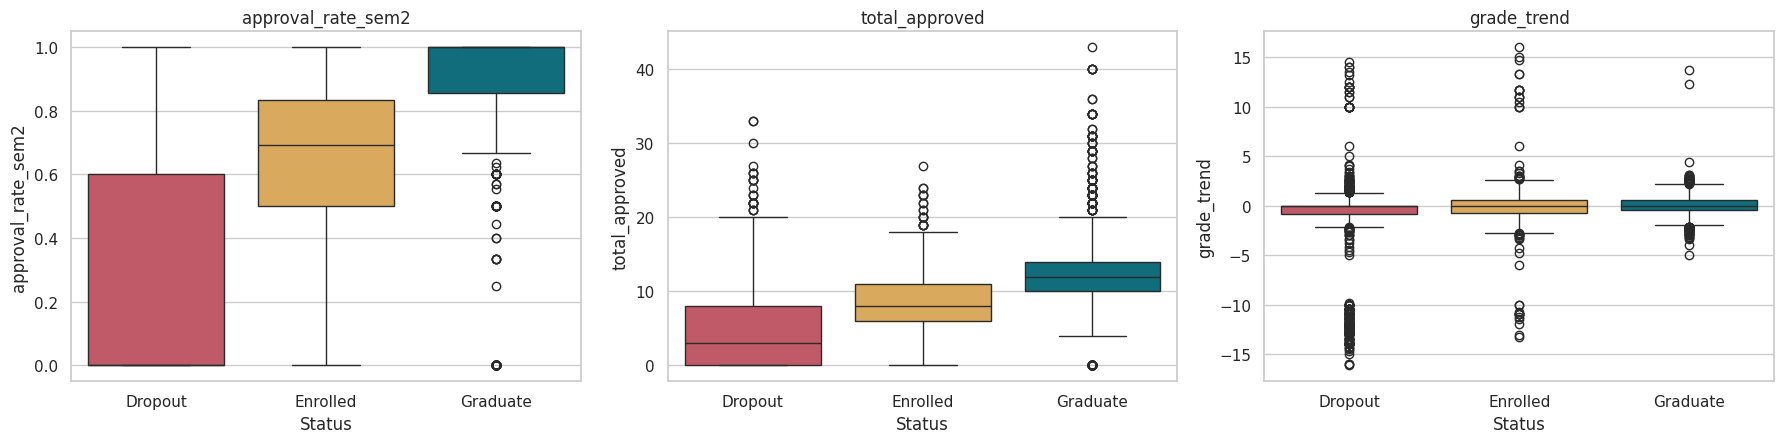

Korelasi fitur turunan dengan Dropout:


,is_dropout
approval_rate_sem1,-0.591
approval_rate_sem2,-0.659
total_approved,-0.537
total_enrolled,-0.134
grade_trend,-0.225
approved_trend,-0.175


In [30]:
tmp = df_fe.copy()
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for ax, col in zip(axes, ["approval_rate_sem2", "total_approved", "grade_trend"]):
    sns.boxplot(data=tmp, x="Status", y=col, order=STATUS_ORDER, palette=PALETTE, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

tmp["is_dropout"] = (tmp["Status"] == "Dropout").astype(int)
print("Korelasi fitur turunan dengan Dropout:")
tmp[FITUR_TURUNAN + ["is_dropout"]].corr()["is_dropout"].drop("is_dropout").round(3)

**Insight.** `approval_rate_sem2` dan `total_approved` membedakan status dengan jelas. Fitur turunan ini lebih kuat dari fitur asli. `approval_rate_sem2` berkorelasi -0,66 dengan dropout, sedangkan fitur asli terbaik hanya -0,57. Fitur `grade_trend` menangkap mahasiswa yang nilainya jatuh di semester 2.

## 3.2 Encoding target

Kita mengubah label teks menjadi angka: `Dropout = 0`, `Enrolled = 1`, `Graduate = 2`.

In [31]:
y = df_fe["Status"].map(TARGET_MAP).astype(int)
X = df_fe.drop(columns=["Status"])
print(TARGET_MAP)
print("Fitur akhir:", X.shape[1])
y.value_counts().sort_index().rename(INV_TARGET_MAP)

{'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
Fitur akhir: 42


,count
Status,
Dropout,1421
Enrolled,794
Graduate,2209


## 3.3 Pengelompokan fitur dan preprocessing

| Kelompok | Perlakuan | Alasan |
|----------|-----------|--------|
| Numerik | `StandardScaler` | Membantu Logistic Regression. Tidak merugikan model pohon. |
| Biner (0/1) | Dibiarkan | Sudah berbentuk 0/1. |
| Nominal (kode kategori) | `OneHotEncoder` | Urutan kode tidak bermakna. Kategori langka (kurang dari 15 data) digabung. |

Encoder dan scaler masuk ke dalam `Pipeline`. Cara ini mencegah kebocoran data karena transformasi hanya belajar dari data latih.

In [32]:
def buat_preprocessor(kolom):
    nominal = [c for c in NOMINAL if c in kolom]
    biner = [c for c in BINARY if c in kolom]
    numerik = [c for c in kolom if c not in nominal + biner]
    return ColumnTransformer([
        ("num", StandardScaler(), numerik),
        ("bin", "passthrough", biner),
        ("nom", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=15,
                              sparse_output=False), nominal),
    ])

FITUR_MODEL = X.columns.tolist()
prep_contoh = buat_preprocessor(FITUR_MODEL).fit(X)
print("Fitur sebelum preprocessing :", len(FITUR_MODEL))
print("Fitur setelah preprocessing :", len(prep_contoh.get_feature_names_out()))

Fitur sebelum preprocessing : 42
Fitur setelah preprocessing : 134


## 3.4 Pembagian data latih dan data uji

Kita memakai rasio 80:20 dengan `stratify`, sehingga proporsi kelas sama di kedua bagian.

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Data latih:", X_train.shape, " | Data uji:", X_test.shape)
pd.DataFrame({
    "latih_%": y_train.value_counts(normalize=True).sort_index() * 100,
    "uji_%": y_test.value_counts(normalize=True).sort_index() * 100,
}).rename(index=INV_TARGET_MAP).round(1)

Data latih: (3539, 42)  | Data uji: (885, 42)


,latih_%,uji_%
Status,,
Dropout,32.100,32.100
Enrolled,17.900,18.000
Graduate,49.900,49.900


# 4. Modeling

Kita melatih empat algoritma:
- **Logistic Regression** sebagai baseline.
- **Random Forest**.
- **XGBoost**.
- **LightGBM**.

Untuk mengatasi ketidakseimbangan kelas, kita memakai `class_weight="balanced"` (Logistic Regression, Random Forest, LightGBM) dan `sample_weight` (XGBoost). Metrik utama adalah **macro F1**. Metrik ini memperlakukan ketiga kelas secara setara, termasuk kelas `Enrolled` yang kecil.

## 4.1 Baseline dan validasi silang (5-fold)

In [34]:
def buat_model(nama):
    if nama == "Logistic Regression":
        return LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced")
    if nama == "Random Forest":
        return RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced",
                                      n_jobs=-1, random_state=RANDOM_STATE)
    if nama == "XGBoost":
        return XGBClassifier(objective="multi:softprob", n_estimators=300, learning_rate=0.05,
                             max_depth=4, subsample=0.8, colsample_bytree=0.8,
                             eval_metric="mlogloss", n_jobs=-1, random_state=RANDOM_STATE)
    if nama == "LightGBM":
        return LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, subsample=0.8,
                              subsample_freq=1, colsample_bytree=0.8, class_weight="balanced",
                              n_jobs=-1, random_state=RANDOM_STATE, verbose=-1)
    raise ValueError(nama)


def buat_pipeline(nama, kolom=None):
    kolom = FITUR_MODEL if kolom is None else kolom
    return Pipeline([("prep", buat_preprocessor(kolom)), ("model", buat_model(nama))])


def fit_params(nama, y_data):
    """XGBoost tidak punya class_weight untuk multikelas, jadi kita pakai sample_weight."""
    if nama == "XGBoost":
        return {"model__sample_weight": compute_sample_weight("balanced", y_data)}
    return {}


NAMA_MODEL = ["Logistic Regression", "Random Forest", "XGBoost", "LightGBM"]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

hasil_cv = []
for nama in NAMA_MODEL:
    cv = cross_validate(buat_pipeline(nama), X_train, y_train, cv=skf, n_jobs=1,
                        scoring=["accuracy", "f1_macro"], params=fit_params(nama, y_train))
    hasil_cv.append({"Model": nama,
                     "CV Accuracy": cv["test_accuracy"].mean(), "CV Accuracy (std)": cv["test_accuracy"].std(),
                     "CV Macro F1": cv["test_f1_macro"].mean(), "CV Macro F1 (std)": cv["test_f1_macro"].std()})
tabel_cv = pd.DataFrame(hasil_cv).set_index("Model")
tabel_cv

,CV Accuracy,CV Accuracy (std),CV Macro F1,CV Macro F1 (std)
Model,,,,
Logistic Regression,0.755,0.013,0.714,0.016
Random Forest,0.777,0.011,0.716,0.016
XGBoost,0.778,0.015,0.738,0.016
LightGBM,0.779,0.013,0.732,0.015


## 4.2 Hyperparameter tuning

Kita menjalankan `RandomizedSearchCV` untuk ketiga model pohon (3-fold, metrik macro F1). Pencarian acak menghemat waktu dibanding grid search.

In [35]:
ruang_param = {
    "Random Forest": {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [None, 8, 12, 16],
        "model__min_samples_leaf": [1, 2, 4, 6],
        "model__max_features": ["sqrt", 0.3, 0.5],
    },
    "XGBoost": {
        "model__n_estimators": [200, 300, 400],
        "model__learning_rate": [0.02, 0.05, 0.1],
        "model__max_depth": [3, 4, 5, 6],
        "model__subsample": [0.7, 0.8, 1.0],
        "model__colsample_bytree": [0.5, 0.7, 0.9],
        "model__min_child_weight": [1, 3, 5],
        "model__reg_lambda": [1, 3, 5],
    },
    "LightGBM": {
        "model__n_estimators": [200, 300, 400],
        "model__learning_rate": [0.02, 0.05, 0.1],
        "model__num_leaves": [7, 15, 31],
        "model__min_child_samples": [10, 20, 40],
        "model__subsample": [0.7, 0.8, 1.0],
        "model__colsample_bytree": [0.5, 0.7, 0.9],
        "model__reg_lambda": [0, 1, 5],
    },
}

model_tuned, ringkas_tuning = {}, []
for nama, grid in ruang_param.items():
    cari = RandomizedSearchCV(buat_pipeline(nama), grid, n_iter=8, scoring="f1_macro",
                              cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
                              random_state=RANDOM_STATE, n_jobs=1, refit=True)
    cari.fit(X_train, y_train, **fit_params(nama, y_train))
    model_tuned[nama] = cari.best_estimator_
    ringkas_tuning.append({"Model": nama, "Best CV Macro F1": cari.best_score_,
                           "Best params": {k.replace("model__", ""): v for k, v in cari.best_params_.items()}})

model_tuned["Logistic Regression"] = buat_pipeline("Logistic Regression").fit(X_train, y_train)
ringkas_tuning = pd.DataFrame(ringkas_tuning).set_index("Model")
pd.set_option("display.max_colwidth", 200)
ringkas_tuning

,Best CV Macro F1,Best params
Model,,
Random Forest,0.716,"{'n_estimators': 500, 'min_samples_leaf': 4, 'max_features': 0.3, 'max_depth': 8}"
XGBoost,0.739,"{'subsample': 1.0, 'reg_lambda': 3, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.02, 'colsample_bytree': 0.7}"
LightGBM,0.731,"{'subsample': 1.0, 'reg_lambda': 1, 'num_leaves': 31, 'n_estimators': 300, 'min_child_samples': 20, 'learning_rate': 0.02, 'colsample_bytree': 0.7}"


# 5. Evaluation

## 5.1 Perbandingan model pada data uji

Data uji belum pernah dilihat model selama pelatihan maupun tuning.

In [36]:
def evaluasi(model, X_eval, y_eval):
    pred = model.predict(X_eval)
    proba = model.predict_proba(X_eval)
    return {
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision (macro)": precision_score(y_eval, pred, average="macro"),
        "Recall (macro)": recall_score(y_eval, pred, average="macro"),
        "F1 (macro)": f1_score(y_eval, pred, average="macro"),
        "F1 (weighted)": f1_score(y_eval, pred, average="weighted"),
        "ROC-AUC (OvR)": roc_auc_score(y_eval, proba, multi_class="ovr"),
        "Recall Dropout": recall_score(y_eval, pred, labels=[0], average=None)[0],
    }

semua = {f"{n} (tuned)" if n != "Logistic Regression" else n: m for n, m in model_tuned.items()}
tabel_uji = pd.DataFrame({n: evaluasi(m, X_test, y_test) for n, m in semua.items()}).T
tabel_uji.sort_values("F1 (macro)", ascending=False)

,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),ROC-AUC (OvR),Recall Dropout
Random Forest (tuned),0.739,0.709,0.711,0.701,0.749,0.886,0.687
LightGBM (tuned),0.745,0.702,0.708,0.701,0.752,0.890,0.711
XGBoost (tuned),0.737,0.698,0.701,0.694,0.745,0.889,0.694
Logistic Regression,0.719,0.686,0.692,0.680,0.732,0.881,0.697


In [37]:
for nama, model in semua.items():
    print("=" * 70)
    print(nama)
    print("=" * 70)
    print(classification_report(y_test, model.predict(X_test), target_names=STATUS_ORDER, digits=3))

Random Forest (tuned)
              precision    recall  f1-score   support

     Dropout      0.844     0.687     0.757       284
    Enrolled      0.439     0.635     0.519       159
    Graduate      0.844     0.810     0.827       442

    accuracy                          0.739       885
   macro avg      0.709     0.711     0.701       885
weighted avg      0.771     0.739     0.749       885

XGBoost (tuned)
              precision    recall  f1-score   support

     Dropout      0.811     0.694     0.748       284
    Enrolled      0.435     0.591     0.501       159
    Graduate      0.847     0.817     0.832       442

    accuracy                          0.737       885
   macro avg      0.698     0.701     0.694       885
weighted avg      0.762     0.737     0.745       885

LightGBM (tuned)
              precision    recall  f1-score   support

     Dropout      0.795     0.711     0.751       284
    Enrolled      0.450     0.591     0.511       159
    Graduate      0.

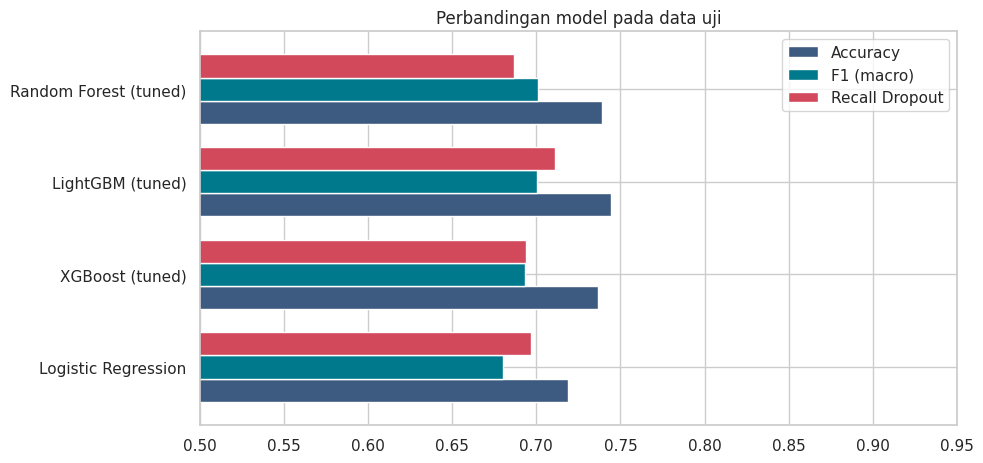

In [38]:
ax = tabel_uji[["Accuracy", "F1 (macro)", "Recall Dropout"]].sort_values("F1 (macro)").plot(
    kind="barh", figsize=(10, 4.8), color=["#3d5a80", "#00798c", "#d1495b"], width=.75)
ax.set_xlim(0.5, 0.95); ax.set_title("Perbandingan model pada data uji")
plt.tight_layout(); plt.show()

## 5.2 Memilih model terbaik

Kita memilih model dengan **macro F1 validasi silang tertinggi** pada tahap tuning. Pemilihan memakai data latih saja, sehingga data uji tetap jujur.

In [39]:
kandidat = ringkas_tuning["Best CV Macro F1"]
NAMA_TERBAIK = kandidat.idxmax()
model_terbaik = model_tuned[NAMA_TERBAIK]
print("Model terbaik (berdasarkan CV macro F1):", NAMA_TERBAIK)
print(kandidat.round(4).to_string())

Model terbaik (berdasarkan CV macro F1): XGBoost
Model
Random Forest   0.716
XGBoost         0.739
LightGBM        0.731


MODEL TERBAIK: XGBoost
              precision    recall  f1-score   support

     Dropout      0.811     0.694     0.748       284
    Enrolled      0.435     0.591     0.501       159
    Graduate      0.847     0.817     0.832       442

    accuracy                          0.737       885
   macro avg      0.698     0.701     0.694       885
weighted avg      0.762     0.737     0.745       885



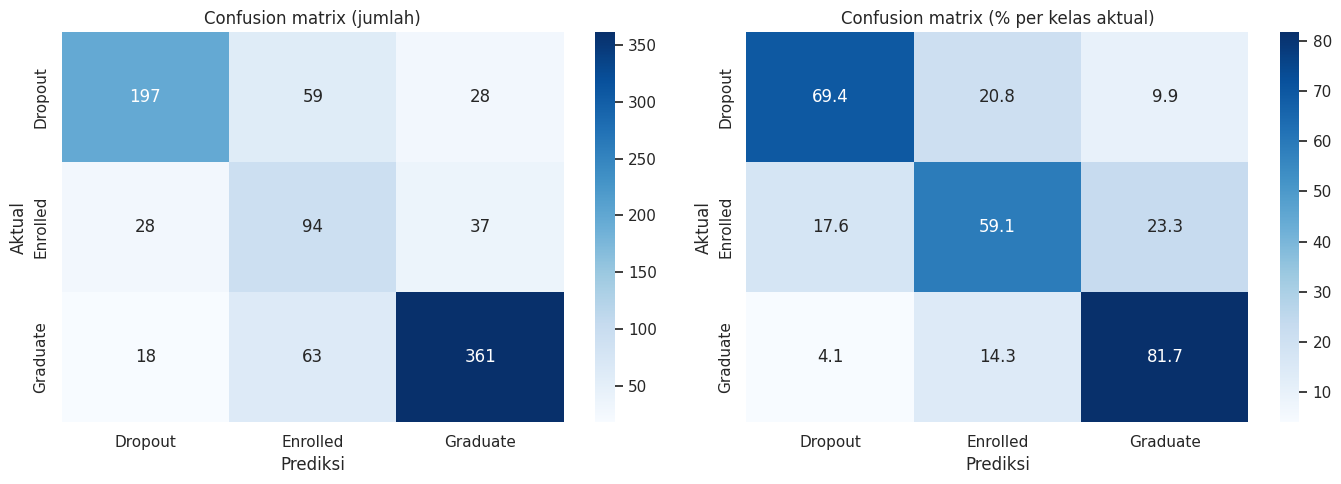

In [40]:
pred_test = model_terbaik.predict(X_test)
print(f"MODEL TERBAIK: {NAMA_TERBAIK}")
print(classification_report(y_test, pred_test, target_names=STATUS_ORDER, digits=3))

cm = confusion_matrix(y_test, pred_test)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=STATUS_ORDER, yticklabels=STATUS_ORDER, ax=ax[0])
ax[0].set_title("Confusion matrix (jumlah)")
sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Blues", xticklabels=STATUS_ORDER, yticklabels=STATUS_ORDER, ax=ax[1])
ax[1].set_title("Confusion matrix (% per kelas aktual)")
for a in ax:
    a.set_xlabel("Prediksi"); a.set_ylabel("Aktual")
plt.tight_layout(); plt.show()

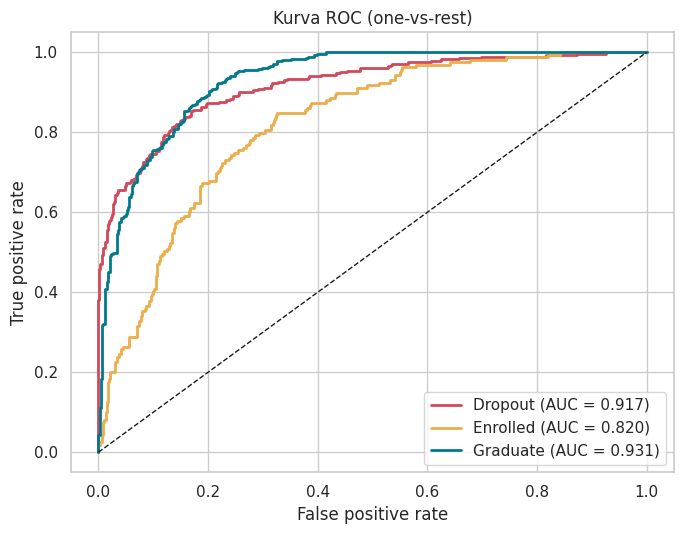

In [41]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

proba_test = model_terbaik.predict_proba(X_test)
y_bin = label_binarize(y_test, classes=[0, 1, 2])
fig, ax = plt.subplots(figsize=(7, 5.5))
for i, s in enumerate(STATUS_ORDER):
    fpr, tpr, _ = roc_curve(y_bin[:, i], proba_test[:, i])
    ax.plot(fpr, tpr, color=PALETTE[s], lw=2, label=f"{s} (AUC = {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("Kurva ROC (one-vs-rest)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 5.3 Fitur paling berpengaruh

Kita memakai *permutation importance* pada fitur asli (sebelum one-hot). Metode ini mengacak satu fitur dan mengukur penurunan macro F1. Hasilnya mudah dibaca oleh pihak bisnis.

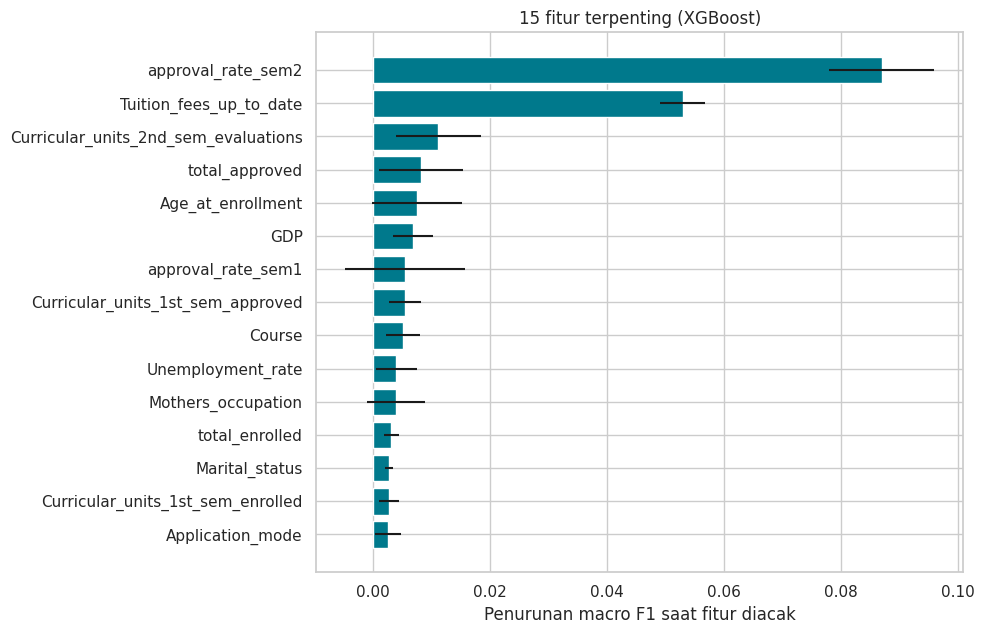

,fitur,penurunan_F1,std
0,approval_rate_sem2,0.087,0.009
1,Tuition_fees_up_to_date,0.053,0.004
2,Curricular_units_2nd_sem_evaluations,0.011,0.007
3,total_approved,0.008,0.007
4,Age_at_enrollment,0.008,0.008
5,GDP,0.007,0.003
6,approval_rate_sem1,0.006,0.010
7,Curricular_units_1st_sem_approved,0.006,0.003
8,Course,0.005,0.003
9,Unemployment_rate,0.004,0.003


In [42]:
perm = permutation_importance(model_terbaik, X_test, y_test, scoring="f1_macro",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
imp = (pd.DataFrame({"fitur": X_test.columns, "penurunan_F1": perm.importances_mean, "std": perm.importances_std})
       .sort_values("penurunan_F1", ascending=False).reset_index(drop=True))

top15 = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(top15["fitur"], top15["penurunan_F1"], xerr=top15["std"], color="#00798c")
ax.set_xlabel("Penurunan macro F1 saat fitur diacak")
ax.set_title(f"15 fitur terpenting ({NAMA_TERBAIK})")
plt.tight_layout(); plt.show()
imp.head(15)

## 5.4 Analisis kesalahan

Kita melihat kelas mana yang paling sering salah diprediksi dan seberapa yakin model.

In [43]:
err = pd.DataFrame({"aktual": y_test.map(INV_TARGET_MAP).values,
                    "prediksi": pd.Series(pred_test).map(INV_TARGET_MAP).values})
print("Pasangan kesalahan terbanyak (aktual -> prediksi):")
(err[err["aktual"] != err["prediksi"]].value_counts().rename("jumlah").reset_index())

Pasangan kesalahan terbanyak (aktual -> prediksi):


,aktual,prediksi,jumlah
0,Graduate,Enrolled,63
1,Dropout,Enrolled,59
2,Enrolled,Graduate,37
3,Dropout,Graduate,28
4,Enrolled,Dropout,28
5,Graduate,Dropout,18


In [44]:
yakin = proba_test.max(axis=1)
benar = pred_test == y_test.values
bins = pd.cut(yakin, [0, .5, .6, .7, .8, .9, 1.0])
kal = pd.DataFrame({"bin": bins, "benar": benar}).groupby("bin", observed=True)["benar"].agg(["mean", "size"])
kal.columns = ["akurasi", "jumlah"]
kal.index.name = "keyakinan model"
kal

,akurasi,jumlah
keyakinan model,,
"(0.0, 0.5]",0.412,68
"(0.5, 0.6]",0.511,135
"(0.6, 0.7]",0.460,100
"(0.7, 0.8]",0.748,159
"(0.8, 0.9]",0.860,193
"(0.9, 1.0]",0.974,230


## 5.5 Skenario deteksi dini

Jaya Jaya Institut ingin mendeteksi dropout **secepat mungkin**. Tetapi fitur semester baru tersedia setelah semester berjalan. Kita menguji tiga titik waktu:

| Skenario | Fitur yang tersedia |
|----------|--------------------|
| Saat pendaftaran | Demografi, keuangan, jalur masuk. |
| Akhir semester 1 | Ditambah kinerja semester 1. |
| Akhir semester 2 | Semua fitur (model utama). |

Kita memakai algoritma yang sama dengan model terbaik, lengkap dengan parameter hasil tuning.

In [45]:
sem2_kolom = [c for c in X.columns if "2nd_sem" in c or c.endswith("sem2")
              or c in ["total_approved", "total_enrolled", "grade_trend", "approved_trend"]]
akademik_kolom = [c for c in X.columns if "Curricular_units" in c] + FITUR_TURUNAN

skenario = {
    "Saat pendaftaran": [c for c in X.columns if c not in akademik_kolom],
    "Akhir semester 1": [c for c in X.columns if c not in sem2_kolom],
    "Akhir semester 2": X.columns.tolist(),
}

baris = []
for nama_s, kolom in skenario.items():
    pipa = Pipeline([("prep", buat_preprocessor(kolom)),
                     ("model", clone(model_terbaik.named_steps["model"]))])
    pipa.fit(X_train[kolom], y_train, **fit_params(NAMA_TERBAIK, y_train))
    m = evaluasi(pipa, X_test[kolom], y_test)
    baris.append({"Skenario": nama_s, "Jumlah fitur": len(kolom), "Accuracy": m["Accuracy"],
                  "F1 (macro)": m["F1 (macro)"], "Recall Dropout": m["Recall Dropout"],
                  "ROC-AUC (OvR)": m["ROC-AUC (OvR)"]})
tabel_skenario = pd.DataFrame(baris).set_index("Skenario")
tabel_skenario

,Jumlah fitur,Accuracy,F1 (macro),Recall Dropout,ROC-AUC (OvR)
Skenario,,,,,
Saat pendaftaran,24,0.584,0.549,0.567,0.773
Akhir semester 1,31,0.711,0.667,0.665,0.866
Akhir semester 2,42,0.737,0.694,0.694,0.889


## 5.6 Insight hasil modeling

**1. Semua model berkinerja mirip.** Akurasi uji berkisar 72-75% dan ROC-AUC sekitar 0,89. Ketiga model pohon unggul tipis atas Logistic Regression. Selisih antar model pohon masih dalam rentang simpangan baku validasi silang (sekitar 0,015). Jadi tidak ada pemenang yang benar-benar jelas.

**2. XGBoost terpilih.** XGBoost punya macro F1 validasi silang tertinggi (0,739), jadi kita memilihnya tanpa melihat data uji. Pada data uji XGBoost mencapai akurasi 73,7%, macro F1 0,694, dan ROC-AUC 0,889. LightGBM dan Random Forest sedikit lebih tinggi di data uji (macro F1 0,701). Selisih ini wajar akibat variasi data.

**3. Dropout terdeteksi dengan baik.** Presisi kelas `Dropout` sebesar 0,81 dan recall 0,69. Dari 100 mahasiswa yang diprediksi dropout, sekitar 81 benar-benar dropout. Model menangkap sekitar 69 dari setiap 100 dropout aktual.

**4. Kelas `Enrolled` paling sulit.** F1 hanya 0,50 dan presisi 0,44. Kesalahan terbanyak adalah `Graduate` diprediksi `Enrolled` (63 kasus) dan `Dropout` diprediksi `Enrolled` (59 kasus). Mahasiswa `Enrolled` berada di antara dua kelompok lain, sehingga polanya tumpang tindih. Sekitar 21% dropout aktual (59 dari 284) lolos sebagai `Enrolled`.

**5. Dua faktor mendominasi.** Permutation importance menunjukkan `approval_rate_sem2` (penurunan F1 0,087) dan `Tuition_fees_up_to_date` (0,053). Fitur lain berkontribusi di bawah 0,012 per fitur. Temuan ini sejalan dengan EDA: kelulusan mata kuliah dan status pembayaran menentukan risiko.

**6. Keyakinan model dapat dipakai sebagai filter.** Prediksi dengan keyakinan di atas 0,9 benar 97,4% (230 kasus). Prediksi dengan keyakinan di bawah 0,7 benar hanya 41-51%. Kasus yang tidak yakin sebaiknya ditinjau manual oleh staf akademik.

**7. Deteksi dini layak dilakukan di akhir semester 1.** Model dengan data pendaftaran saja lemah (akurasi 58,4%, macro F1 0,549). Setelah ditambah kinerja semester 1, kinerja naik tajam (akurasi 71,1%, macro F1 0,667, ROC-AUC 0,866). Hasil ini mendekati model penuh (akurasi 73,7%). Karena itu institusi dapat menjalankan peringatan dini **tepat setelah semester 1**, tanpa menunggu semester 2.

**8. Skor risiko terkalibrasi baik.** Pada tahap ekspor, mahasiswa dengan risiko `Tinggi` ternyata 90,8% dropout. Kelompok `Sedang` 46,3% dan `Rendah` 9,3%.

**Keterbatasan.**
- Dataset berasal dari satu institusi dan satu periode. Model perlu diuji ulang sebelum dipakai pada kohort baru.
- Model menunjukkan **hubungan**, bukan sebab-akibat. Menurunkan tunggakan tidak otomatis menurunkan dropout.
- Target `Enrolled` tidak final. Sebagian mahasiswa ini nantinya lulus atau dropout.

# 6. Ekspor model dan data dashboard

## 6.1 Menyimpan model untuk Streamlit

Kita melatih ulang pipeline terbaik pada **seluruh data** (latih + uji) agar model produksi memakai semua informasi. Metrik evaluasi di atas tetap berasal dari model yang dilatih pada data latih saja.

File `model/model.joblib` memuat model, daftar fitur, nilai default, pilihan kategori, dan kamus label.

In [46]:
Path("model").mkdir(exist_ok=True)

model_final = clone(model_terbaik)
model_final.fit(X, y, **fit_params(NAMA_TERBAIK, y))

fitur_input = [c for c in X.columns if c not in FITUR_TURUNAN]
default_nilai = {}
for c in fitur_input:
    default_nilai[c] = (int(X[c].mode().iloc[0]) if (c in NOMINAL or c in BINARY or X[c].nunique() <= 12)
                        else float(X[c].median()))

bundle = {
    "model": model_final,
    "model_name": NAMA_TERBAIK,
    "fitur_input": fitur_input,
    "defaults": default_nilai,
    "opsi_nominal": {c: sorted(int(v) for v in X[c].unique()) for c in NOMINAL},
    "rentang": {c: [float(X[c].min()), float(X[c].max())] for c in fitur_input if c not in NOMINAL + BINARY},
    "labels": {"marital": MARITAL, "course": COURSE, "app_mode": APP_MODE, "prev_qual": PREV_QUAL},
    "inv_target_map": INV_TARGET_MAP,
    "metrics_test": {k: float(v) for k, v in evaluasi(model_terbaik, X_test, y_test).items()},
}
joblib.dump(bundle, "model/model.joblib", compress=3)

with open("model/metrics.json", "w", encoding="utf-8") as f:
    json.dump({"model": NAMA_TERBAIK, "test_metrics": bundle["metrics_test"],
               "cv_tuning": {k: float(v) for k, v in ringkas_tuning["Best CV Macro F1"].items()}}, f, indent=2)

print("Model tersimpan:", Path("model/model.joblib").stat().st_size // 1024, "KB")

Model tersimpan: 1295 KB


In [47]:
# Uji muat ulang: hasil harus sama dengan model di memori
cek = joblib.load("model/model.joblib")
contoh = X.iloc[[0, 1, 2]]
print(cek["model"].predict_proba(contoh).round(3))
print([INV_TARGET_MAP[i] for i in cek["model"].predict(contoh)], "| aktual:", df["Status"].iloc[:3].tolist())

[[0.661 0.198 0.141]
 [0.085 0.071 0.844]
 [0.987 0.011 0.002]]
['Dropout', 'Graduate', 'Dropout'] | aktual: ['Dropout', 'Graduate', 'Dropout']


## 6.2 Data untuk dashboard (Looker Studio / Tableau / Metabase)

Kita mengekspor data dengan label yang mudah dibaca. Kita juga menambahkan **skor risiko dropout** hasil prediksi *out-of-fold* (validasi silang 5-fold). Setiap mahasiswa dinilai oleh model yang **tidak pernah melihat** mahasiswa tersebut. Dengan begitu skor risiko jujur dan tidak bocor.

In [48]:
proba_oof = cross_val_predict(clone(model_terbaik), X, y, cv=skf, method="predict_proba",
                              params=fit_params(NAMA_TERBAIK, y), n_jobs=1)

dash = df.copy()
dash.insert(0, "Student_ID", np.arange(1, len(dash) + 1))
dash["Course_name"] = dash["Course"].map(COURSE)
dash["Application_mode_name"] = dash["Application_mode"].map(APP_MODE)
dash["Marital_status_name"] = dash["Marital_status"].map(MARITAL)
dash["Previous_qualification_name"] = dash["Previous_qualification"].map(PREV_QUAL)
for col, lab in BIN_LABELS.items():
    dash[f"{col}_label"] = dash[col].map(lab)
dash["Age_group"] = pd.cut(dash["Age_at_enrollment"], [0, 19, 22, 25, 30, 100],
                           labels=["<=19", "20-22", "23-25", "26-30", ">30"]).astype(str)
dash["Approval_rate_sem1"] = df_fe["approval_rate_sem1"]
dash["Approval_rate_sem2"] = df_fe["approval_rate_sem2"]
dash["Total_approved"] = df_fe["total_approved"]
dash["Grade_trend"] = df_fe["grade_trend"]
dash["Risk_score_dropout"] = proba_oof[:, 0].round(4)
dash["Risk_level"] = pd.cut(dash["Risk_score_dropout"], [-0.01, 0.3, 0.6, 1.01],
                            labels=["Rendah", "Sedang", "Tinggi"]).astype(str)
dash["Predicted_status"] = pd.Series(proba_oof.argmax(axis=1)).map(INV_TARGET_MAP).values

dash.to_csv("dashboard_data.csv", index=False, encoding="utf-8")
print("dashboard_data.csv:", dash.shape)

oof_acc = (dash["Predicted_status"] == dash["Status"]).mean()
print(f"Akurasi out-of-fold: {oof_acc:.3f}")
pd.crosstab(dash["Risk_level"], dash["Status"], normalize="index").mul(100).round(1).reindex(["Rendah", "Sedang", "Tinggi"])

dashboard_data.csv: (4424, 58)
Akurasi out-of-fold: 0.773


Status,Dropout,Enrolled,Graduate
Risk_level,,,
Rendah,9.300,19.700,71.000
Sedang,46.300,35.400,18.300
Tinggi,90.800,6.800,2.400


**Cara membaca.** Semakin tinggi `Risk_level`, semakin besar porsi mahasiswa yang benar-benar dropout. Tim akademik dapat memakai kolom ini sebagai daftar prioritas bimbingan.

# 7. Kesimpulan

Ringkasan hasil dan rekomendasi lengkap tersedia di `README.md`.